# Feature Engineering pour la Segmentation des Profils Journaliers

## Dataset: Individual Household Electric Power Consumption

### UCI Machine Learning Repository - ID: 235

**Période :** Décembre 2006 - Novembre 2010 (4 ans de données)

---

## Construction de Signatures Énergétiques à partir de Séries Temporelles de Consommation Électrique Résidentielle

### OBJECTIFS

1. **Introduction et Positionnement Scientifique**
2. **Objectif Scientifique de l'Étape**
3. **Hypothèse de Représentativité Journalière**
4. **Étape 1 - Transformation Temporelle**
5. **Étape 2 - Variables Statistiques (Tendance Centrale & Dispersion)**
6. **Étape 3 - Variables de Forme de Charge**
7. **Étape 4 - Extraction des Variables de Pics**
8. **Étape 5 - Variables Électriques et Physiques**
9. **Étape 6 - Variables Temporelles et Contextuelles**
10. **Étape 7 - Construction du Dataset Final**
11. **Étape 8 - Analyse des Corrélations**
12. **Étape 9 - Normalisation**
13. **Étape 10 - Validation Scientifique des Features**

---

**AUTEUR : ENANGA DANIEL CHRISTIAN**

In [2]:
# Imports et chargement des données UCI
import os
import urllib.request
import zipfile
import warnings
from io import StringIO

import numpy as np
import pandas as pd
from scipy import stats
from scipy.signal import find_peaks
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import requests
from scipy.signal import find_peaks # Import find_peaks pour la détection de pics
warnings.filterwarnings('ignore')

# Configuration matplotlib
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
matplotlib.rcParams['figure.dpi'] = 300
matplotlib.rcParams['savefig.dpi'] = 600
matplotlib.rcParams['figure.figsize'] = (14, 8)

print("Bibliothèques chargées")

Bibliothèques chargées


## 1. INTRODUCTION ET POSITIONNEMENT SCIENTIFIQUE

Ce document présente la méthodologie de **Feature Engineering** adaptée à la granularité des données disponibles( Par minutes) dans le cadre du travail de segmentation énergétique des ménages. À ce stade, le travail entre dans la phase centrale de construction des **signatures énergétiques** qui serviront ensuite au clustering. L'objectif n'est plus simplement de nettoyer les données, mais de transformer les séries temporelles brutes en représentations compactes, physiquement interprétables et exploitables pour la segmentation.

Dans cette méthodologie, chaque journée est considérée comme une **observation énergétique représentative** (Chaque journée est traitée comme une observation énergétique independante permettant de construire des profils journaliers répresentatifs.). Autrement dit :

> **1 journée = 1 individu statistique**
> décrit par plusieurs variables énergétiques construites

Cette approche, bien que non conventionnelle en termes d'échantillonnage (puisqu'elle repose sur une seule série temporelle longue découpée en observations journalières), est justifiée par la richesse des données disponibles et la nécessité de maximiser l'exploitation des ressources à disposition. Elle s'inscrit dans une démarche de **data augmentation temporelle** où chaque journée constitue un instantané comportemental unique.

Le document détaille les dix étapes du pipeline complet, depuis la transformation temporelle jusqu'à la validation scientifique des features, en passant par la construction des variables statistiques, de forme, de pics, électriques, temporelles et contextuelles.

---

## 2. OBJECTIF SCIENTIFIQUE DE CETTE ETAPE

L'objectif scientifique de cette étape est de construire un nouveau dataset structuré sous la forme d'une matrice :

$$X \in \mathbb{R}^{D \times N}$$

où :

* **D** = nombre de journées (observations)
* **N** = nombre de features construites (variables)

Chaque ligne de cette matrice doit résumer :

* Le **comportement énergétique** d'une journée complète.
* Sous forme d'une **signature multidimensionnelle** interprétable.
* Permettant une **comparaison inter-journalière** et une segmentation efficace.

Cette représentation matricielle constitue le fondement de toute analyse de clustering ultérieure. La qualité des features construites déterminera directement la pertinence des segments identifiés et l'interprétabilité des profils de consommation.

In [ ]:

# Chemin vers la racine du projet
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Configuration
DATASET_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
DATA_DIR = os.path.join(BASE_DIR, "data", "raw" , "uci")
RAW_FILENAME = "household_power_consumption.txt"

# Creer le dossier de données
os.makedirs(DATA_DIR, exist_ok=True)

# Chemin du fichier
raw_path = os.path.join(DATA_DIR, RAW_FILENAME)

# Télécharger si nécessaire
if not os.path.exists(raw_path):
    print("Téléchargement du dataset en cours...")
    zip_path = os.path.join(DATA_DIR, "dataset.zip")
    urllib.request.urlretrieve(DATASET_URL, zip_path)
    print("Extraction de l'archive...")
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(DATA_DIR)
    os.remove(zip_path)
    print("Dataset telechargé et extrait avec succès!")
else:
    print("Dataset déjà présent localement.")

# Verification
for f in os.listdir(DATA_DIR):
    print(f"  -> {f}")

Dataset déjà présent localement.
  -> household_power_consumption.txt


In [7]:
# Chargement du dataset
# na_values=['?'] est CRITIQUE: le dataset utilise '?' pour les valeurs manquantes
df = pd.read_csv(
    raw_path,
    sep=';',
    na_values=['?', 'nan', 'NaN', ''],
    low_memory=True
)

print("DATASET CHARGEMENT")
print("=" * 60)
print(f"Dimensions: {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Colonnes: {df.columns.tolist()}")
print(f"Types de données:")
print(df.dtypes)

DATASET CHARGEMENT
Dimensions: 2,075,259 lignes x 9 colonnes
Colonnes: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
Types de données:
Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


# 3. Quelques recapitulations de l'analyse d'exploration de données précédente

In [8]:
# Création d'une colonne DateTime pour l'analyse temporelle
df['DateTime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)
print(f"Date de debut: {df['DateTime'].min()}")
print(f"Date de fin:   {df['DateTime'].max()}")
print(f"Durée totale:  {df['DateTime'].max() - df['DateTime'].min()}")
print(f"Nombre total d'heures: {len(df) / 60:.0f}")
print(f"Nombre total de jours:   {len(df) / 1440:.0f}")

Date de debut: 2006-12-16 17:24:00
Date de fin:   2010-11-26 21:02:00
Durée totale:  1441 days 03:38:00
Nombre total d'heures: 34588
Nombre total de jours:   1441


In [9]:
# Colonnes numériques
numeric_cols = [
    'Global_active_power', 'Global_reactive_power', 'Voltage',
    'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3'
]
# l'analyse des valeurs manquantes dans chaque collonne du dataset 
print("VALEURS MANQUANTES PAR COLONNE")
print("=" * 60)

missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(4)

for col in df.columns:
    if missing_counts[col] > 0:
        print(f"  {col:25s}: {missing_counts[col]:>10,}  ({missing_pct[col]:.2f}%)")
    else:
        print(f"  {col:25s}: {missing_counts[col]:>10,}  (0.00%)")

# Vérifier si les manquants sont concomitants
numeric_missing = df[numeric_cols].isnull()
all_same_missing = numeric_missing.all(axis=1).sum()
total_missing_rows = df[numeric_cols[0]].isnull().sum()

print(f"--- Pattern ---")
print(f"Lignes avec manquants:{total_missing_rows:,}")
print(f"Lignes avec TOUS numériques manquants: {all_same_missing:,}")
print(f"Pattern concomitant: {'OUI ✓' if all_same_missing == total_missing_rows else 'NON'}")

VALEURS MANQUANTES PAR COLONNE
  Date                     :          0  (0.00%)
  Time                     :          0  (0.00%)
  Global_active_power      :     25,979  (1.25%)
  Global_reactive_power    :     25,979  (1.25%)
  Voltage                  :     25,979  (1.25%)
  Global_intensity         :     25,979  (1.25%)
  Sub_metering_1           :     25,979  (1.25%)
  Sub_metering_2           :     25,979  (1.25%)
  Sub_metering_3           :     25,979  (1.25%)
  DateTime                 :          0  (0.00%)
--- Pattern ---
Lignes avec manquants:25,979
Lignes avec TOUS numériques manquants: 25,979
Pattern concomitant: OUI ✓


In [10]:
# Identifications des jours avec des valeurs manquantes
df_temp = df.copy()
df_temp['has_missing'] = df_temp['Global_active_power'].isnull()
missing_rows = df_temp[df_temp['has_missing']]
if len(missing_rows) > 0:
    missing_by_date = missing_rows.groupby(missing_rows['DateTime'].dt.date).size()
    print(f"Nombre de jours avec manquants: {len(missing_by_date)}")
    print(f"Top des 10 prémiers jours avec le plus de manquants:")
    print(missing_by_date.sort_values(ascending=False).head(10))

    print(f"Intervalle de Date des valeurs manquantes: {missing_by_date.index.min()} au {missing_by_date.index.max()}")
    print(f"Max des valeurs manquantes sur un jour: {missing_by_date.max()} minutes ({missing_by_date.max()/60:.1f} heures)")

Nombre de jours avec manquants: 82
Top des 10 prémiers jours avec le plus de manquants:
DateTime
2007-04-29    1440
2009-06-14    1440
2010-01-13    1440
2010-08-21    1440
2010-09-27    1440
2010-09-26    1440
2010-08-20    1440
2010-08-18    1440
2010-08-19    1440
2007-04-28    1419
dtype: int64
Intervalle de Date des valeurs manquantes: 2006-12-21 au 2010-10-24
Max des valeurs manquantes sur un jour: 1440 minutes (24.0 heures)


In [11]:
# corréction de l'exploration des données précédente
# Exclusion des jours incomplets (des jours où on a < 1380 minutes soit 24 heures , sont Exclues)
print("\n=== EXCLUSION JOURS INCOMPLETS ===")

# Initialiser df_clean à partir du jeu de données original
# et création d'une clé de date simple pour compter les jours complets.

df_clean = df.copy()
df_clean['Date_ymd'] = pd.to_datetime(
    df_clean['Date'], format='%d/%m/%Y', errors='coerce'
).dt.date

daily_counts = df_clean.groupby('Date_ymd').size()
complete_days = daily_counts[daily_counts >= 1380].index
print(f"Jours totaux: {len(daily_counts)}")
print(f"Jours complets (≥1380 min): {len(complete_days)}")
print(f"Jours incomplets exclus: {len(daily_counts) - len(complete_days)}")

df_clean = df_clean[df_clean['Date_ymd'].isin(complete_days)].copy()
print(f"Lignes après exclusion jours incomplets: {len(df_clean):,}")


=== EXCLUSION JOURS INCOMPLETS ===
Jours totaux: 1442
Jours complets (≥1380 min): 1440
Jours incomplets exclus: 2
Lignes après exclusion jours incomplets: 2,073,600


In [12]:
# la corrélation entre global_active_power et global_intensity ( P = U * I ), r = 0,999 , donc on aura une info redondante 
# Élimination de  Global_intensity (colinéarité parfaite P_active ↔ I)

print("\n===GESTION COLINÉARITÉ ===")
print(f"Corrélation P_active ↔ Intensity: {df_clean['Global_active_power'].corr(df_clean['Global_intensity']):.4f}")
print("→ Global_intensity sera EXCLUE du feature engineering (redondante avec P_active)")
# On garde dans df_clean pour référence mais on marquera à exclure
features_to_exclude = ['Global_intensity']  # Car P = U×I, donc info redondante

print("\n=== Dataset propre final ===")
print(f"Lignes: {len(df_clean):,}")
print(f"Jours complets: {df_clean['Date_ymd'].nunique()}")
print(f"Période: {df_clean['DateTime'].min()} au {df_clean['DateTime'].max()}")



===GESTION COLINÉARITÉ ===
Corrélation P_active ↔ Intensity: 0.9989
→ Global_intensity sera EXCLUE du feature engineering (redondante avec P_active)

=== Dataset propre final ===
Lignes: 2,073,600
Jours complets: 1440
Période: 2006-12-17 00:00:00 au 2010-11-25 23:59:00


Profils journaliers: 1440 jours × 24 heures


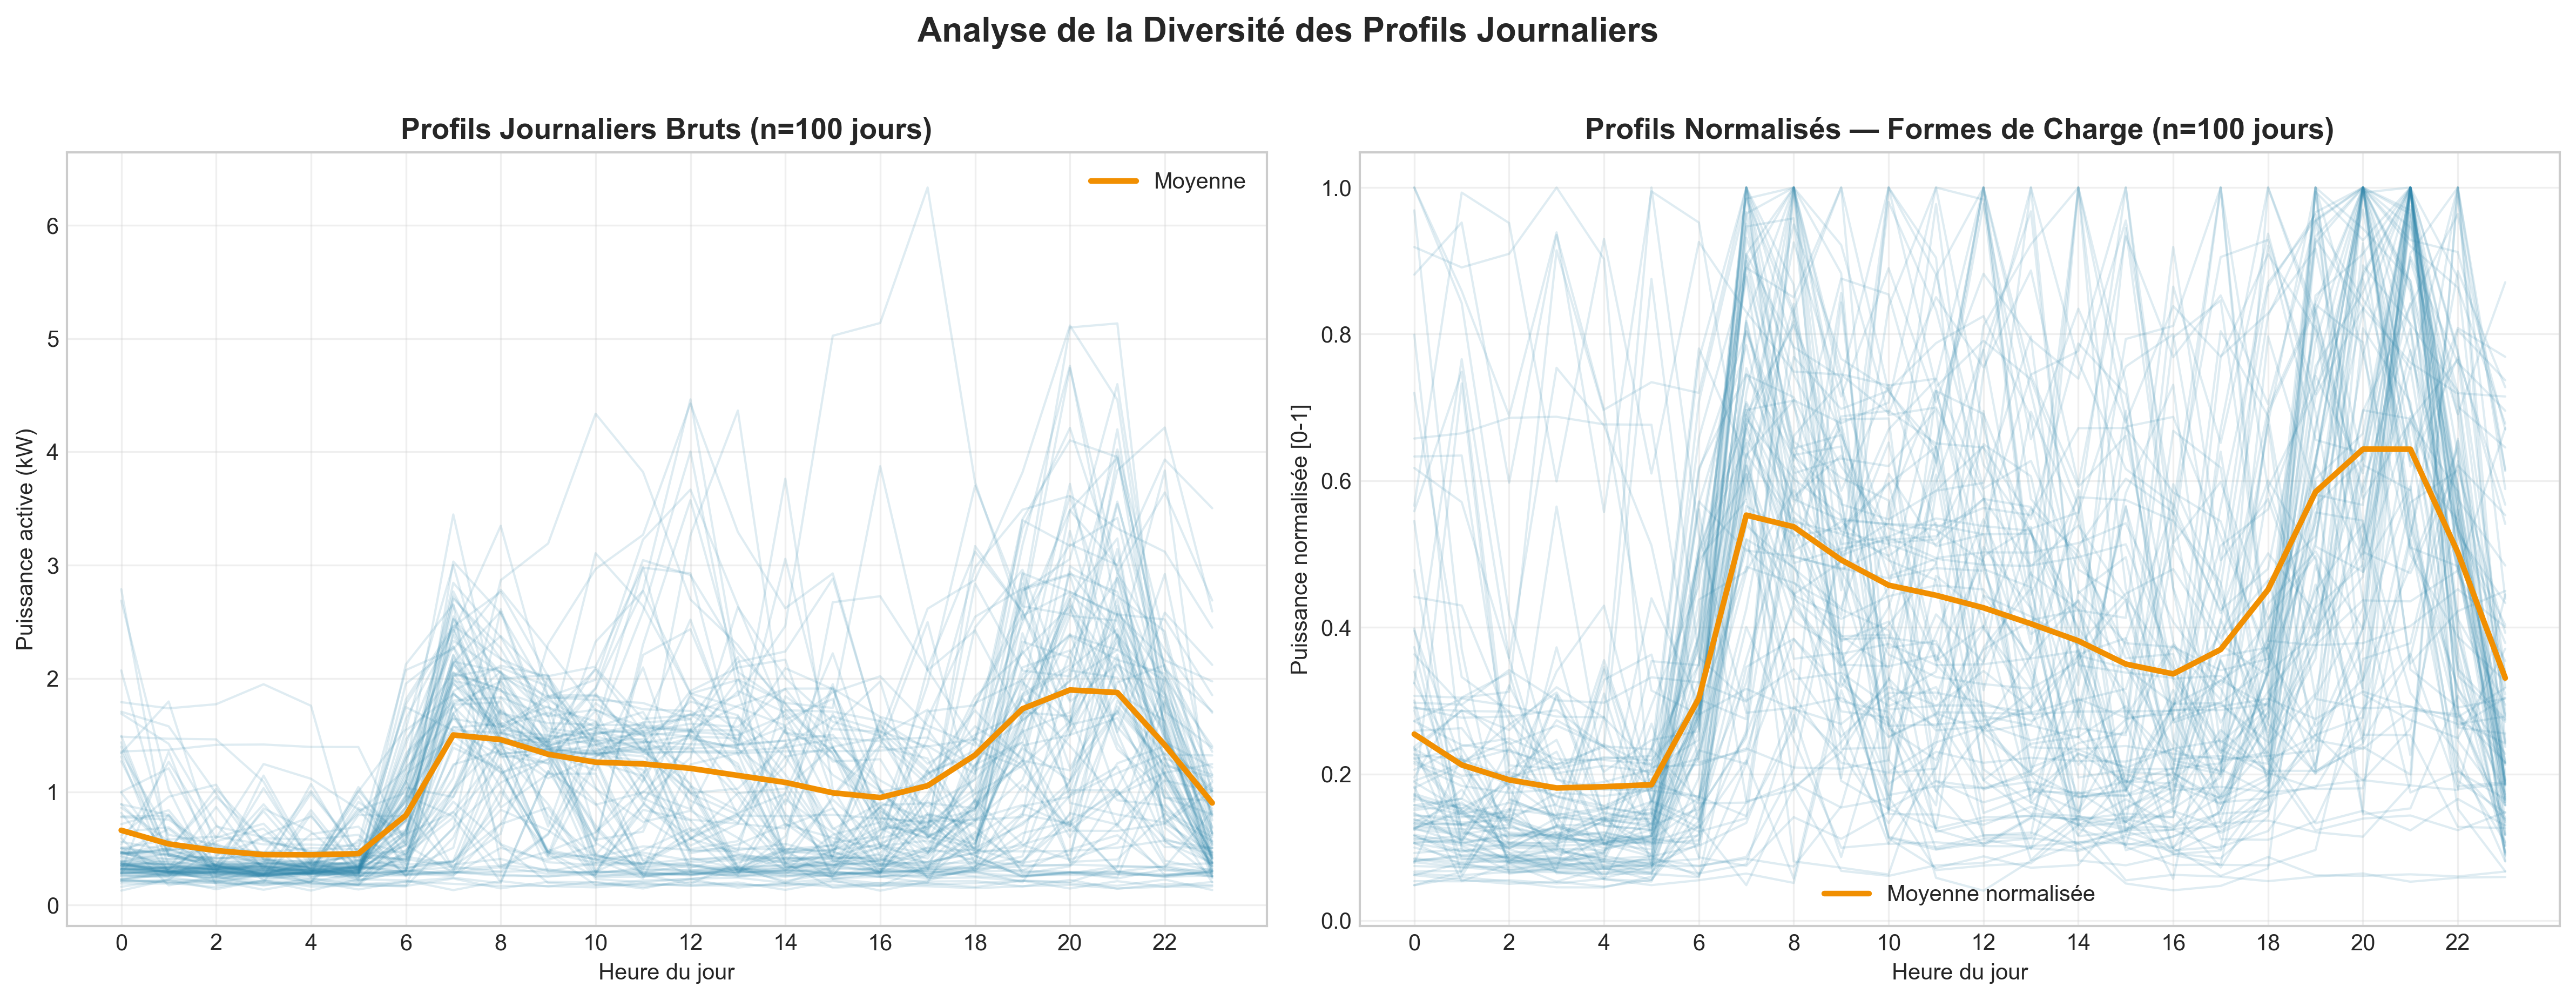

✓ Figure sauvegardée: 07_daily_profiles_diversity.png


In [18]:
# Maintenant visualisons un peu la diversité des formes de profils de charge journqlières superposés (échantillon de 100 jours)

IMAGES_DIR = os.path.join(BASE_DIR, "results", "images")
OUT_DIR = os.path.join(BASE_DIR, "data", "processed") 
os.makedirs(OUT_DIR, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

# 1. Créer DateTime propre
df_clean['Hour'] = df_clean['DateTime'].dt.hour
df_clean['Month'] = df_clean['DateTime'].dt.month
df_clean['Year'] = df_clean['DateTime'].dt.year

# Calcul des profils horaires par jour
daily_profiles = df_clean.groupby(['Date_ymd', 'Hour'])['Global_active_power'].mean().unstack()
print(f"Profils journaliers: {daily_profiles.shape[0]} jours × {daily_profiles.shape[1]} heures")

# Normaliser chaque profil pour voir les FORMES (indépendamment du niveau)
daily_profiles_norm = daily_profiles.div(daily_profiles.max(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A Gauche: Profils bruts (échantillon de 100 jours)
ax1 = axes[0]
sample_days = np.random.choice(daily_profiles.index, size=min(100, len(daily_profiles)), replace=False)
for day in sample_days:
    ax1.plot(daily_profiles.columns, daily_profiles.loc[day], alpha=0.15, color='#2E86AB', linewidth=1)
# Moyenne
mean_profile = daily_profiles.mean()
ax1.plot(mean_profile.index, mean_profile.values, color='#F18F01', linewidth=2.5, label='Moyenne')
ax1.set_title('Profils Journaliers Bruts (n=100 jours)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Heure du jour')
ax1.set_ylabel('Puissance active (kW)')
ax1.set_xticks(range(0, 24, 2))
ax1.legend()
ax1.grid(True, alpha=0.3)

# A Droite: Profils normalisés (formes)
ax2 = axes[1]
for day in sample_days:
    ax2.plot(daily_profiles_norm.columns, daily_profiles_norm.loc[day], alpha=0.15, color='#2E86AB', linewidth=1)
mean_norm = daily_profiles_norm.mean()
ax2.plot(mean_norm.index, mean_norm.values, color='#F18F01', linewidth=2.5, label='Moyenne normalisée')
ax2.set_title('Profils Normalisés — Formes de Charge (n=100 jours)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Heure du jour')
ax2.set_ylabel('Puissance normalisée [0-1]')
ax2.set_xticks(range(0, 24, 2))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Analyse de la Diversité des Profils Journaliers', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/07_daily_profiles_diversity.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"✓ Figure sauvegardée: 07_daily_profiles_diversity.png")

### Analyse de la Diversité des Profils Journaliers

> La comparaison des profils bruts et normalisés montre que les ménages ne se distinguent pas uniquement par la quantité d’énergie consommée, mais aussi par leurs habitudes d’utilisation. Les données brutes mettent en évidence des niveaux de consommation très différents, tandis que la normalisation permet surtout d’observer la forme des profils de charge au cours de la journée. Cette étape aide ainsi l’algorithme de clustering à identifier des comportements similaires, indépendamment de la puissance totale consommée.

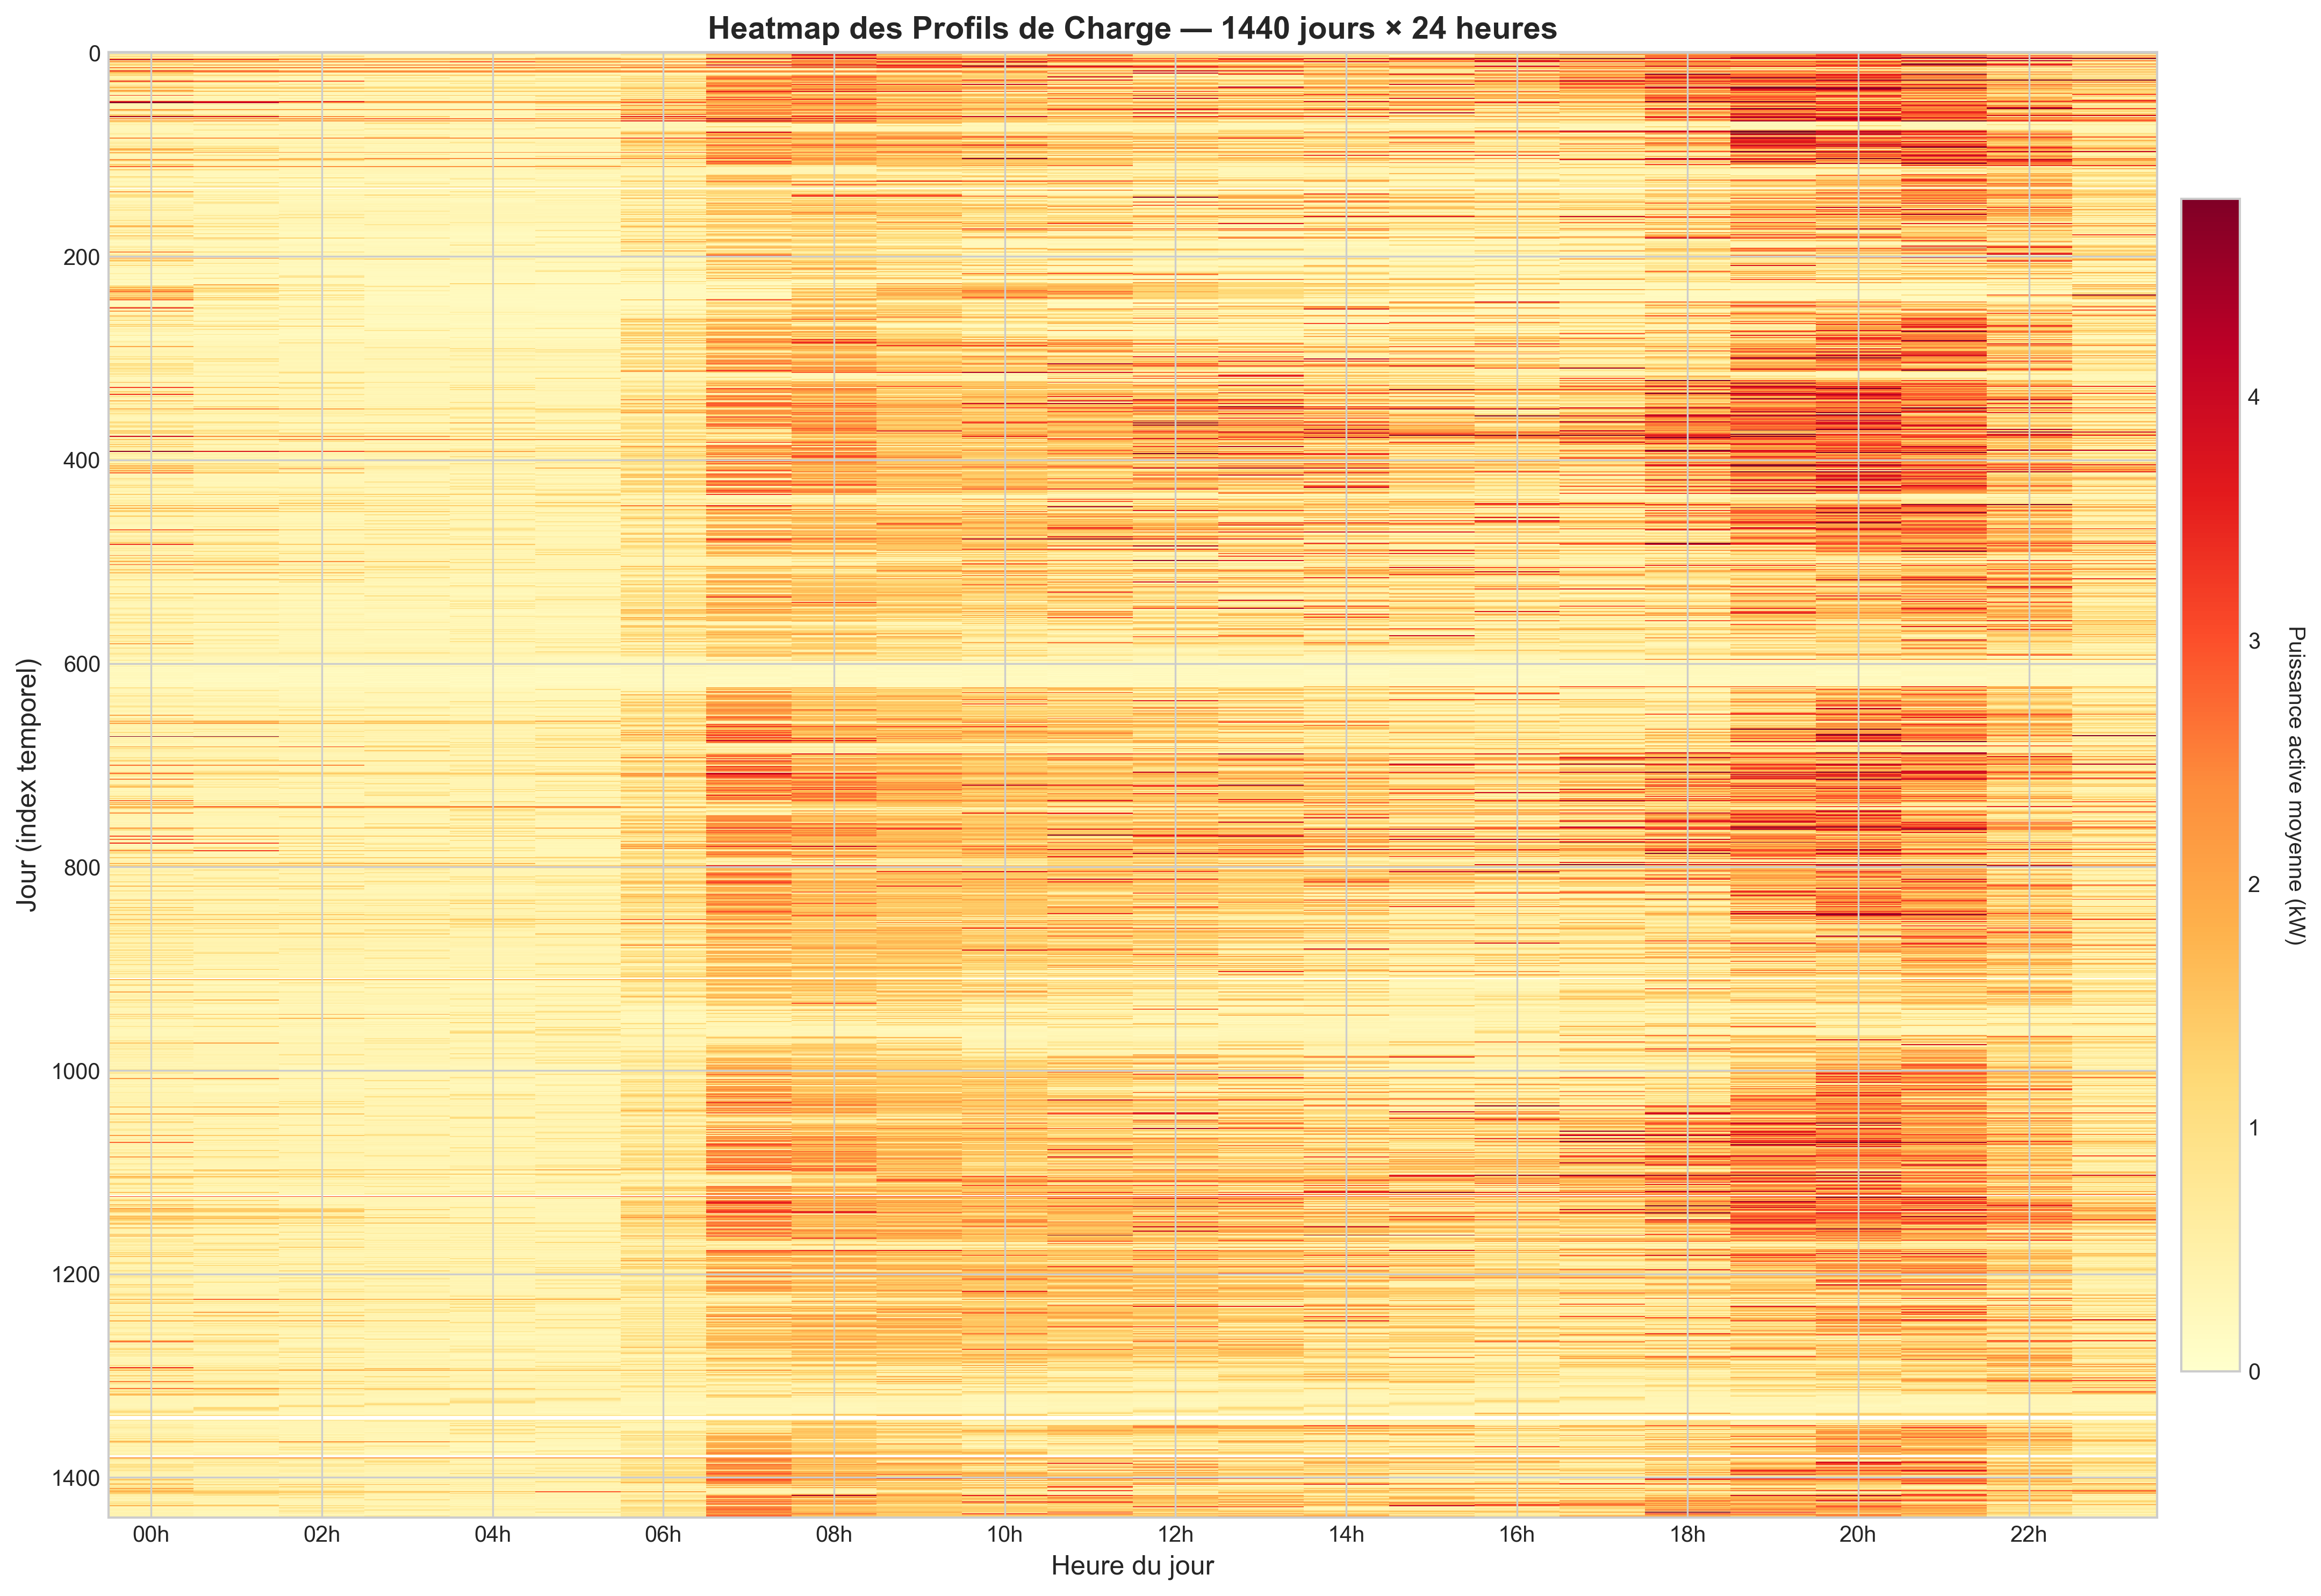

✓ Figure sauvegardée: 08_heatmap_daily_profiles.png


In [19]:
# le Heatmap 1440 jours × 24 heures (Visualisation de la carte de témperature de nos profils de charges)

fig, ax = plt.subplots(figsize=(16, 10))

# Réindexer par jour numérique pour l'affichage
daily_profiles_filled = daily_profiles.ffill(axis=1).bfill(axis=1)

# Affichage du heatmap
im = ax.imshow(daily_profiles_filled.values, aspect='auto', cmap='YlOrRd', 
               interpolation='nearest', vmin=0, vmax=daily_profiles_filled.quantile(0.99).max())

ax.set_title('Heatmap des Profils de Charge — 1440 jours × 24 heures', fontsize=14, fontweight='bold')
ax.set_xlabel('Heure du jour', fontsize=12)
ax.set_ylabel('Jour (index temporel)', fontsize=12)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f'{h:02d}h' for h in range(0, 24, 2)])

# Colorbar
cbar = plt.colorbar(im, ax=ax, shrink=0.8, pad=0.01)
cbar.set_label('Puissance active moyenne (kW)', rotation=270, labelpad=20)

plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/08_heatmap_daily_profiles.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"✓ Figure sauvegardée: 08_heatmap_daily_profiles.png")


### Analyse de la Heatmap

> La heatmap met en évidence des habitudes de consommation qui se répètent dans le temps. On observe notamment des pics récurrents le matin et le soir, correspondant aux périodes d’activité domestique. Certaines périodes présentent également une consommation plus élevée, traduisant l’influence des saisons. Cette visualisation montre donc que les comportements énergétiques restent globalement stables, même si certaines variations apparaissent selon le contexte ou le type de journée.


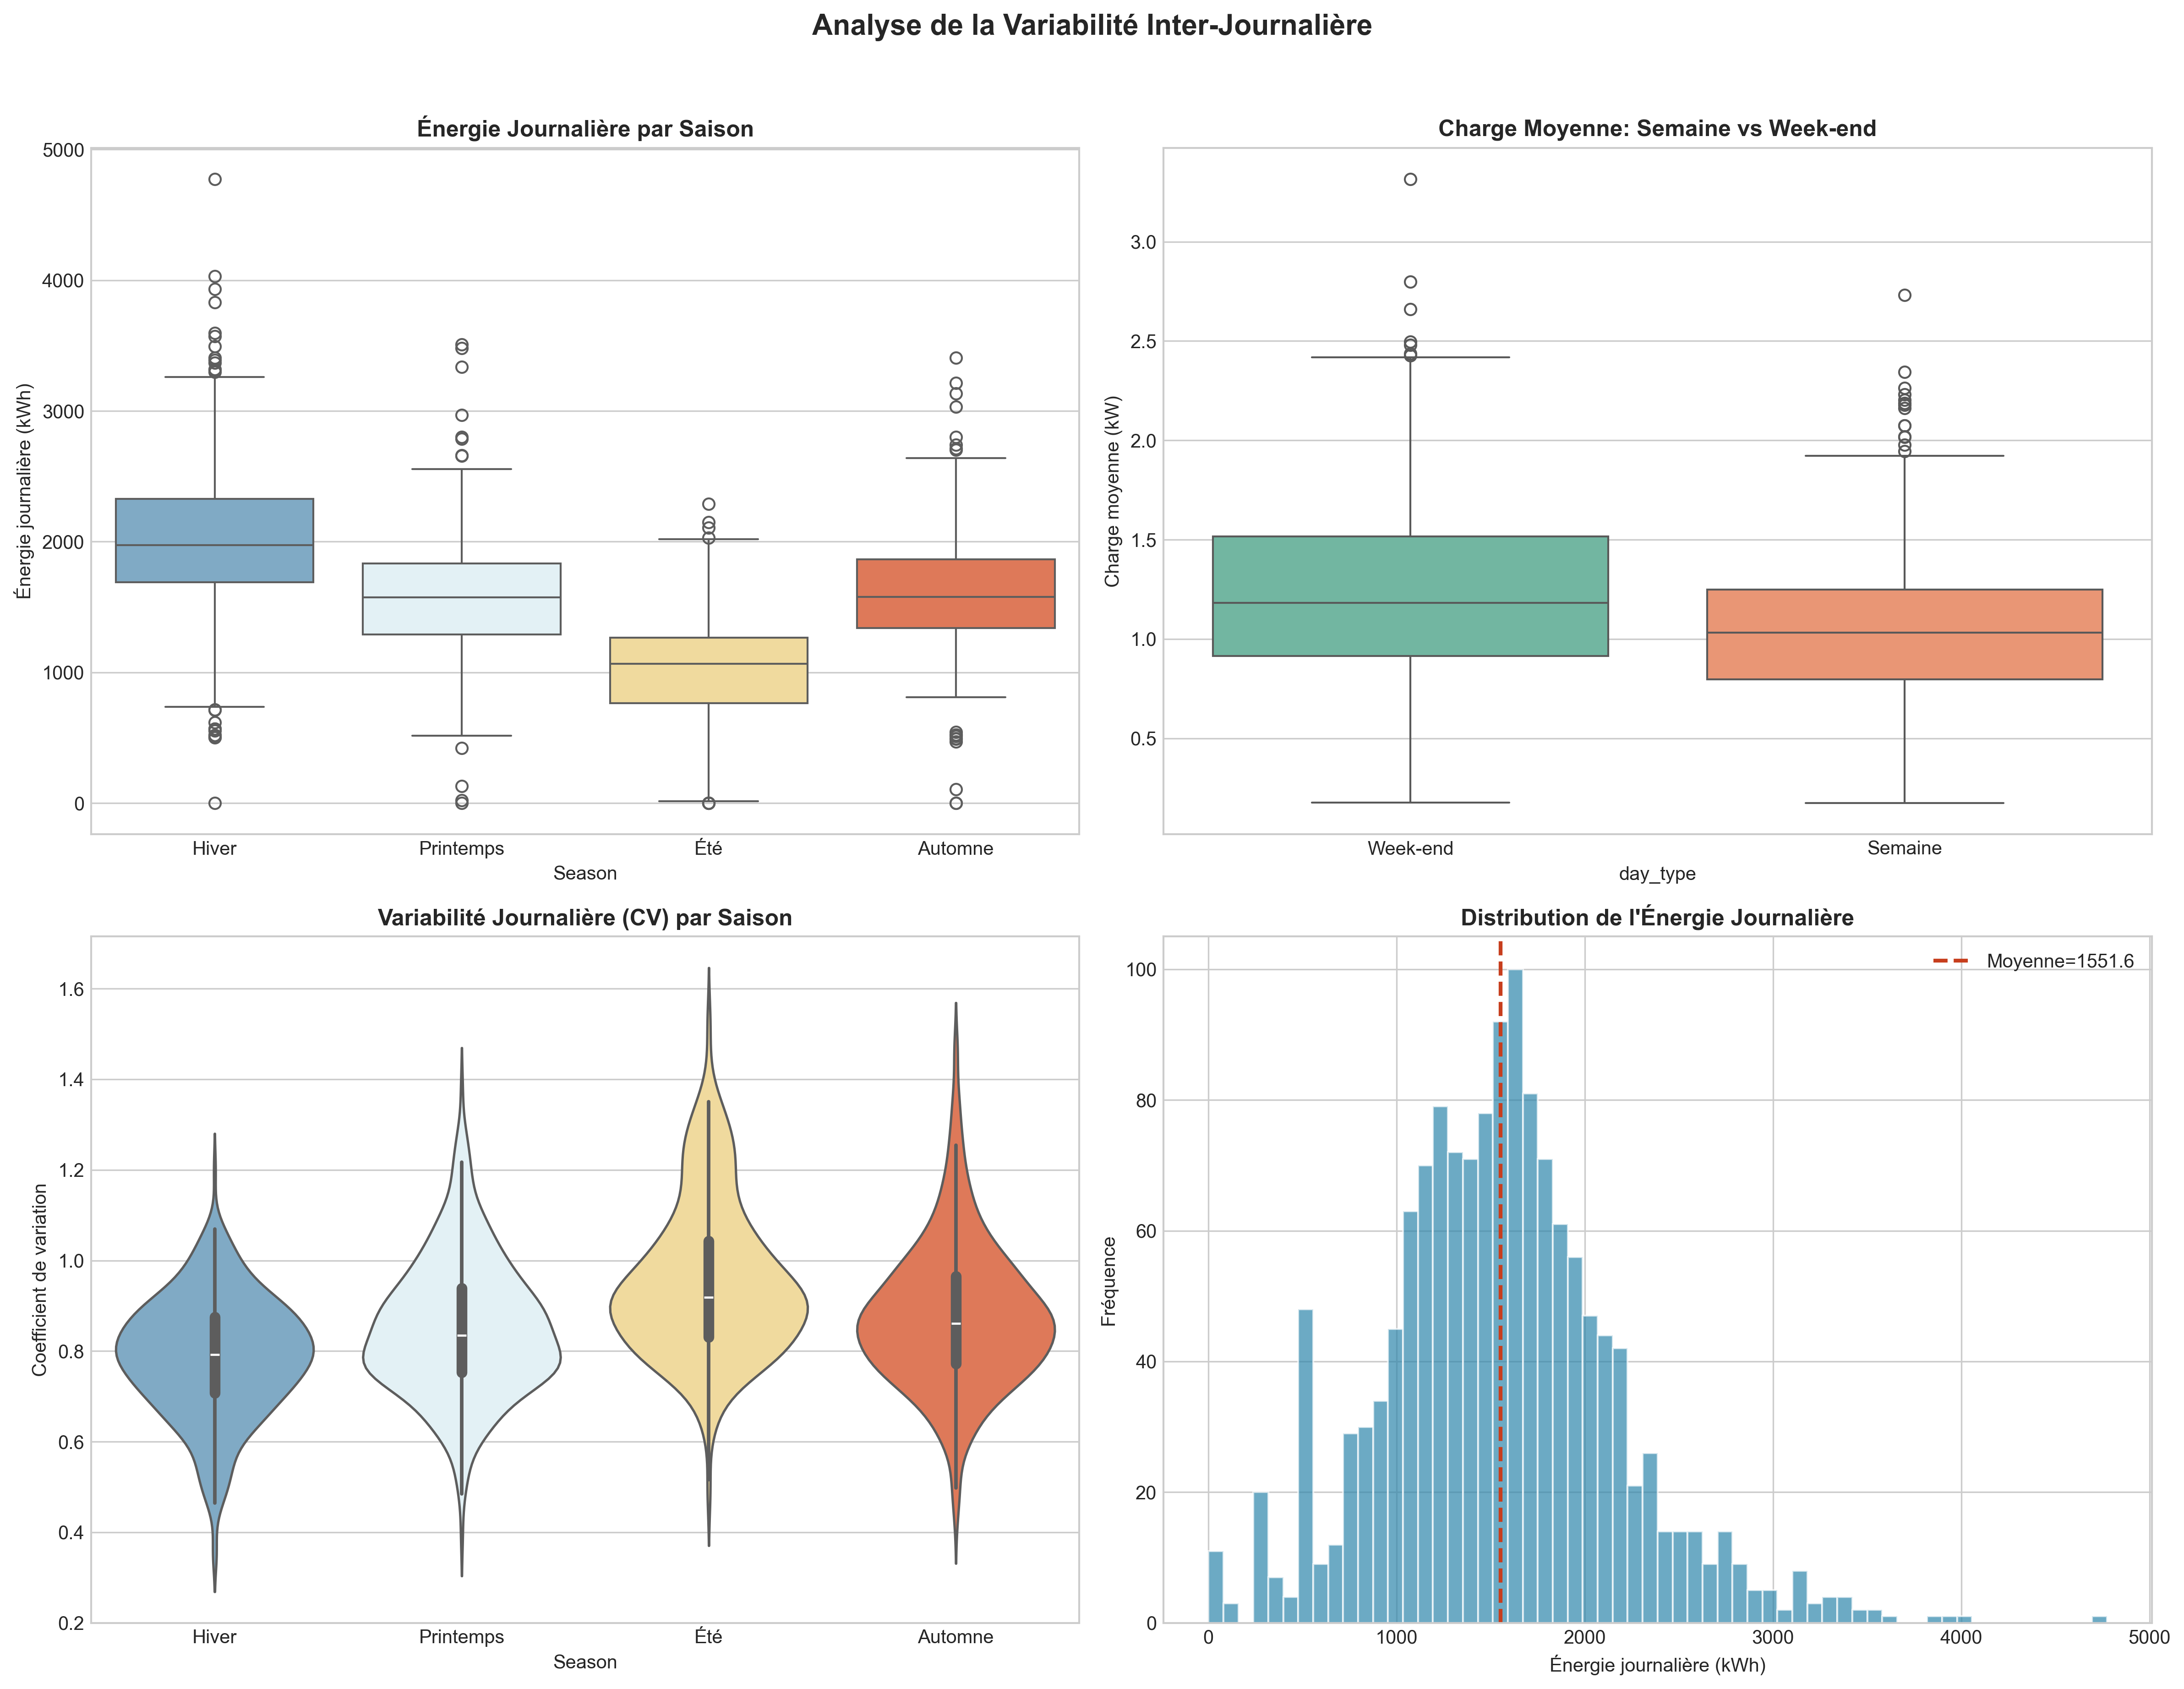

=== Statistiques Inter-Journalières ===
Énergie journalière moyenne: 1551.62 ± 617.66 kWh
Rapport Hiver/Été: 1.98
Rapport Weekend/Semaine: 1.17
CV moyen: 0.868 ± 0.164


In [20]:
# Variabilité inter-journalière
# Boxplots(Diagramme en boite) de consommation journalière pqr saison et type de jour 
# calcule des statistiques journalières 

daily_stats = df_clean.groupby('Date_ymd').agg({
    'Global_active_power': ['sum', 'mean', 'std', 'max'],
    'Sub_metering_1': 'sum',
    'Sub_metering_2': 'sum', 
    'Sub_metering_3': 'sum',
}).reset_index()
daily_stats.columns = ['Date_ymd', 'daily_energy', 'mean_load', 'std_load', 'max_load', 
                        'sub1_energy', 'sub2_energy', 'sub3_energy']

# Ajout du contexte temporel
daily_stats['Date_ymd'] = pd.to_datetime(daily_stats['Date_ymd'])
daily_stats['Month'] = daily_stats['Date_ymd'].dt.month
daily_stats['DayOfWeek'] = daily_stats['Date_ymd'].dt.dayofweek  # 0=Lundi
daily_stats['IsWeekend'] = daily_stats['DayOfWeek'].isin([5, 6])
daily_stats['Season'] = daily_stats['Month'].map({12:'Hiver',1:'Hiver',2:'Hiver',
                                                    3:'Printemps',4:'Printemps',5:'Printemps',
                                                    6:'Été',7:'Été',8:'Été',
                                                    9:'Automne',10:'Automne',11:'Automne'})

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Boxplot: Énergie journalière par saison
ax1 = axes[0, 0]
sns.boxplot(data=daily_stats, x='Season', y='daily_energy', order=['Hiver','Printemps','Été','Automne'], 
            palette='RdYlBu_r', ax=ax1)
ax1.set_title('Énergie Journalière par Saison', fontweight='bold')
ax1.set_ylabel('Énergie journalière (kWh)')

# 2. Boxplot: Moyenne de charge par type de jour
ax2 = axes[0, 1]
daily_stats['day_type'] = daily_stats['IsWeekend'].map({True: 'Week-end', False: 'Semaine'})
sns.boxplot(data=daily_stats, x='day_type', y='mean_load', palette='Set2', ax=ax2)
ax2.set_title('Charge Moyenne: Semaine vs Week-end', fontweight='bold')
ax2.set_ylabel('Charge moyenne (kW)')

# 3. Coefficient de variation par saison
ax3 = axes[1, 0]
daily_stats['cv'] = daily_stats['std_load'] / daily_stats['mean_load']
daily_stats['cv'] = daily_stats['cv'].replace([np.inf, -np.inf], np.nan)
sns.violinplot(data=daily_stats, x='Season', y='cv', order=['Hiver','Printemps','Été','Automne'],
               palette='RdYlBu_r', ax=ax3)
ax3.set_title('Variabilité Journalière (CV) par Saison', fontweight='bold')
ax3.set_ylabel('Coefficient de variation')

# 4. Distribution de l'énergie totale
ax4 = axes[1, 1]
ax4.hist(daily_stats['daily_energy'], bins=60, color='#2E86AB', alpha=0.7, edgecolor='white')
ax4.axvline(daily_stats['daily_energy'].mean(), color='#C73E1D', linewidth=2, linestyle='--', label=f'Moyenne={daily_stats["daily_energy"].mean():.1f}')
ax4.set_title('Distribution de l\'Énergie Journalière', fontweight='bold')
ax4.set_xlabel('Énergie journalière (kWh)')
ax4.set_ylabel('Fréquence')
ax4.legend()

plt.suptitle('Analyse de la Variabilité Inter-Journalière', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/09_interdaily_variability.png", dpi=150, bbox_inches='tight')
plt.show()

# Statistiques
print("=== Statistiques Inter-Journalières ===")
print(f"Énergie journalière moyenne: {daily_stats['daily_energy'].mean():.2f} ± {daily_stats['daily_energy'].std():.2f} kWh")
print(f"Rapport Hiver/Été: {daily_stats[daily_stats['Season']=='Hiver']['daily_energy'].mean() / daily_stats[daily_stats['Season']=='Été']['daily_energy'].mean():.2f}")
print(f"Rapport Weekend/Semaine: {daily_stats[daily_stats['IsWeekend']]['daily_energy'].mean() / daily_stats[~daily_stats['IsWeekend']]['daily_energy'].mean():.2f}")
print(f"CV moyen: {daily_stats['cv'].mean():.3f} ± {daily_stats['cv'].std():.3f}")


### Analyse de la Variabilité Inter-journalière

> Les résultats montrent que la consommation électrique varie selon la saison et le type de jour. En hiver, la consommation est généralement plus élevée et plus dispersée, probablement à cause des besoins de chauffage. Les week-ends présentent des profils plus étalés que les jours de semaine, ce qui reflète des habitudes domestiques différentes. Enfin, la variabilité observée en été suggère des comportements moins réguliers. Ces observations confirment l’importance de prendre en compte des facteurs externes, comme la saison ou le type de jour, dans le modèle d’analyse.


# 4. FEATURE ENGINEERING
---

Avant de détailler le pipeline de *feature engineering*, il est essentiel de formaliser l'hypothèse fondatrice qui sous-tend l'ensemble de la démarche.

> **HYPOTHÈSE N°1 : REPRÉSENTATIVITÉ JOURNALIÈRE**
> On suppose qu'une journée de consommation constitue une **unité comportementale exploitable**, permettant de capturer des habitudes énergétiques significatives et suffisamment distinctes pour différencier les différents profils de charge

### Justification théorique :

Cette hypothèse repose sur plusieurs fondements. D'abord, Les activités domestiques s’organisent naturellement autour des rythmes quotidiens des occupants. Les habitudes de lever, de repas, de travail et de sommeil se traduisent par des signatures de charge électrique reconnaissables. Ensuite, la périodicité de 24 heures constitue une échelle temporelle pertinente pour capturer à la fois les variations intra-journalières (heures de pointe, creux) et les différences inter-journalières (weekend vs. semaine, saisonnalité).

Enfin, du point de vue statistique, découper une série longue en observations journalières permet d'atteindre un nombre d'observations suffisant (typiquement 365 à 1440 jours selon la durée de la série) pour appliquer des méthodes de clustering robustes, tout en préservant la cohérence physique des profils.

### Limites et précautions :

Il convient de noter que cette hypothèse implique une certaine **indépendance entre journées consécutives**, ce qui n'est pas strictement vérifié en raison des corrélations temporelles (autocorrélation). Cependant, pour la segmentation, l'objectif est de caractériser des états énergétiques plutôt que de modéliser des transitions. Les éventuelles dépendances seront prises en compte dans l'interprétation des résultats de clustering.

## ETAPE 1 - TRANSFORMATION TEMPORELLE

### Objectif

Transformer la série temporelle minute par minute (ou à la granularité disponible) en observations journalières. Cette étape constitue le pivot entre la phase de prétraitement et la phase de *feature engineering* proprement dite.

### Principe de la transformation

Les données brutes sont structurées sous forme d'une série temporelle continue où chaque ligne représente un instant de mesure avec sa valeur de puissance (et éventuellement d'autres variables). La transformation consiste à regrouper toutes les mesures appartenant à une même journée calendaire.

## RÉSULTAT ATTENDU DE LA TRANSFORMATION

**Avant transformation :**

| datetime | power (kW) |
| --- | --- |
| 2007-01-01 18:01 | 4.216 |
| 2007-01-01 18:02 | 4.534 |
| 2007-01-01 18:03 | 4.412 |
| ... | ... |
| 2007-01-02 00:01 | 3.891 |

**Après transformation :**

| date | Nombre de mesures | Période couverte |
| --- | --- | --- |
| 2007-01-01 | 1440 | 00:00 - 23:59 |
| 2007-01-02 | 1440 | 00:00 - 23:59 |
| 2007-01-03 | 1440 | 00:00 - 23:59 |
| ... | ... | ... |

*Note : Chaque date devient une future ligne du dataset final. Le nombre de mesures par journée dépend de la fréquence d'échantillonnage des données (1440 pour une minute, 86400 pour une seconde, etc.).*

## ÉTAPE 2 - CONSTRUCTION DES VARIABLES STATISTIQUES

Cette étape vise à capturer les propriétés fondamentales de la distribution des valeurs de charge au sein de chaque journée. On distingue deux familles de variables : celles décrivant la **tendance centrale** (niveau global de consommation) et celles décrivant la **dispersion** (stabilité et régularité).

### 1. Variables de Tendance Centrale

Ces variables mesurent le niveau global de consommation électrique au cours de la journée. Elles permettent de discriminer les journées à forte consommation (hiver, week-end) de celles à faible consommation (été, absence des occupants).

| Feature | Formule mathématique | Interprétation physique |
| --- | --- | --- |
| **total_daily_energy** | $E_{tot} = \sum_{t=1}^{T} P(t) \times \Delta t$ | Énergie totale consommée dans la journée (kWh). Mesure l'ampleur globale de la consommation. |
| **mean_load** | $\bar{P} = (1/T) \times \sum_{t=1}^{T} P(t)$ | Puissance moyenne sur la journée (kW). Indique le niveau de charge moyen soutenu. |
| **median_load** | $\tilde{P} = \text{median}(P(1), ..., P(T))$ | Puissance médiane (kW). Moins sensible aux outliers que la moyenne. Représente la valeur centrale typique. |

**Intérêt pour le clustering :**
Ces trois variables permettent de distinguer les profils à forte consommation (ménages avec chauffage électrique, nombreux appareils) des profils sobres. La médiane offre une robustesse supplémentaire face aux pics transitoires qui pourraient fausser la moyenne.


### 2. Variables de Dispersion

Ces variables mesurent la stabilité, les fluctuations et la régularité de la charge électrique au cours de la journée. Elles sont essentielles pour caractériser le comportement dynamique du ménage.

| Feature | Formule mathématique | Interprétation physique |
| --- | --- | --- |
| **std_load** | $\sigma_P = \sqrt{(1/T) \times \sum(P(t) - \bar{P})^2}$ | Écart-type de la charge (kW). Mesure l'amplitude des fluctuations autour de la moyenne. |
| **load_variance** | $\sigma^2_P = (1/T) \times \sum(P(t) - \bar{P})^2$ | Variance de la charge (kW²). Carré de l'écart-type. Plus sensible aux grandes déviations. |
| **load_cv** | $CV = \sigma_P / \bar{P}$ | Coefficient de variation (sans unité). Mesure la variabilité relative, normalisée par la moyenne. |

**Intérêt pour le clustering :**
Un ménage avec des habitudes régulières (routines fixes) présente un profil à faible variance, tandis qu'un ménage avec des usages irréguliers (télétravail intermittent, activités variables) présente une variance élevée. Le coefficient de variation est particulièrement utile car il normalise la dispersion par le niveau moyen, permettant de comparer des ménages de tailles différentes.

> **HYPOTHÈSE N°2 : STABILITÉ ÉNERGÉTIQUE**
> On suppose que la **variabilité de la charge électrique** constitue un descripteur discriminant des profils journaliers. Les ménages présentant des fluctuations importantes sont distincts de ceux avec des profils stables et prévisibles.






# ETAPE 3 - CONSTRUCTION DES VARIABLES DE FORME DE CHARGE

Cette étape vise à décrire la **structure temporelle** de la consommation au-delà des simples statistiques descriptives. Les variables de forme de charge capturent les habitudes de vie, les périodes d'activité et la structure globale du profil journalier. Elles sont particulièrement pertinentes pour la segmentation car elles traduisent directement des comportements résidentiels distincts.

## 1. Facteur de Charge (Load Factor)

Le facteur de charge est une métrique clé en ingénierie électrique qui mesure l'uniformité de la consommation sur une période donnée. Un facteur proche de 1 indique un profil plat et régulier, tandis qu'un facteur faible révèle des pics marqués et des périodes de faible consommation.

> **LoadFactor = Pmoy / Pmax = (Σ P(t) / T) / max(P(t))**

### Interpretation :

* **LF = 1.0** : Profil très plat, consommation quasi-constante (ex: chauffage électrique en hiver, serveurs domestiques)
* **LF = 0.3 - 0.5** : Profil typique résidentiel avec pics matin/soir et creux nocturnes
* **LF < 0.2** : Profil très irrégulier avec pics ponctuels intenses (ex: usage d'appareils puissants intermittents)

## 2. Ratio Jour / Nuit (DayNightRatio)

Cette variable compare la consommation pendant les heures de jour (typiquement 6h-22h) à celle pendant les heures de nuit (22h-6h). Elle révèle les habitudes d'activité du ménage et la présence d'appareils fonctionnant en continu.

> **DayNightRatio = Consojour / Consonuit = (Σt=6h à 22h P(t)) / (Σt=22h à 6h P(t))**

### Interpretation :

* ■ **DNR > 5** : Forte activité diurne, consommation quasi-nulle la nuit (ménage actif, absence nocturne)
* ■ **DNR = 2 - 3** : Profil équilibré avec activité nocturne modérée (chauffage, réfrigérateur)
* ■ **DNR < 1.5** : Activité nocturne significative (travail posté, chauffage continu, éclairage prolongé)

## 3. Pourcentage de Consommation Nocturne (NightPct)

Cette variable complémentaire au ratio jour/nuit exprime la part relative de la consommation nocturne dans la consommation totale de la journée. Elle est particulièrement utile pour identifier les ménages avec des charges de base élevées (appareils en veille, chauffage nocturne).

> **NightPct = Consonuit / Consototale = (Σt=22h à 6h P(t)) / (Σt=0h à 24h P(t))**

### Interpretation :

* ■ **NightPct < 15%** : Charge de base faible, ménage peu consommateur la nuit
* ■ **NightPct = 25 - 35%** : Valeur typique (réfrigérateur, veille électronique)
* ■ **NightPct > 40%** : Charge nocturne dominante (chauffage, climatisation, éclairage prolongé)

## Tableau récapitulatif - Variables de Forme de Charge

| Feature | Type | Interpretation | Interet clustering |
| --- | --- | --- | --- |
| load_factor | Stabilité | Uniformité du profil de charge | Distingue profils plats vs. irréguliers |
| day_night_ratio | Comportement | Rapport consommation jour/nuit | Identifie rythmes d'activité |
| night_pct | Comportement | Part nocturne dans conso totale | Détecte charges de base élevées |

.
>HYPOTHESE N°3 : COMPORTEMENT RÉSIDENTIEL
>On suppose que les **rythmes temporels de consommation** traduisent des comportements résidentiels distincts. Les horaires d'activité, les périodes de présence et les habitudes de vie se reflètent directement dans la distribution temporelle de la charge électrique.

# ETAPE 4 - EXTRACTION DES VARIABLES DE PICS

Cette étape vise à identifier et caractériser les moments de forte sollicitation électrique au cours de la journée. Les pics de consommation sont des indicateurs puissants de l'activité domestique, des routines de vie et de l'intensité des usages. Leur détection et leur caractérisation permettent de discriminer des profils de ménages aux comportements très différents.

### 1. Méthode de Détection des Pics

La détection des pics peut s'effectuer selon deux approches complémentaires :

| Approche | Description | Avantage |
| --- | --- | --- |
| **Maxima locaux** | Détection des points où $P(t) > P(t-1)$ et $P(t) > P(t+1)$ avec un seuil minimal | Robuste au bruit, capture les pics réels |
| **Dépassement de seuil** | Identification des périodes où $P(t) > k \times P_{moy}$ ($k$ typiquement 1.5 à 2.0) | Simple, paramétrable, adapté aux profils variés |


### 2. Variables Extraites

| Feature | Definition | Formule / Methode | Interpretation |
| --- | --- | --- | --- |
| **max_load** | Puissance maximale atteinte dans la journée | $P_{max} = \max(P(t))$ pour $t \in [0, 24h[$ | Indicateur de l'appareil le plus puissant utilisé ou de la simultanéité des usages |
| **hour_peak_morning** | Heure du pic matinal (6h-12h) | $\text{argmax}(P(t))$ pour $t \in [6h, 12h[$ | Réveil, préparation du petit-déjeuner, départ au travail |
| **hour_peak_evening** | Heure du pic du soir (17h-23h) | $\text{argmax}(P(t))$ pour $t \in [17h, 23h[$ | Retour du travail, repas du soir, loisirs domestiques |
| **num_peaks** | Nombre de pics significatifs détectés | $\text{Cardinalité de } \{t \mid P(t) \text{ est un maximum local et } P(t) > \text{seuil}\}$ | Complexité du profil : nombre de cycles d'activité distincts |

### Interpretation des variables de pics :

Ces variables représentent l'**activité domestique**, les **routines de vie** et l'**intensité des usages**. Un ménage avec un pic matinal précoce (6h30) et un pic du soir tardif (21h) présente un profil différent d'un ménage sans pic matinal mais avec un pic du soir à 18h (retour précoce du travail). Le nombre de pics révèle la complexité du rythme de vie : un seul pic (soir) suggère une vie simple, tandis que multiples pics (matin, midi, soir, nuit) indiquent un ménage avec des activités variées ou des horaires décalés.

>HYPOTHÈSE N°4 : ROUTINES TEMPORELLES
>On suppose que les **horaires des pics de consommation** reflètent les habitudes quotidiennes des occupants. Les moments de forte sollicitation électrique correspondent aux transitions entre les différentes phases de la journée (réveil, repas, retour à domicile, coucher).

# Étape 5 : Variables Électriques et Physiques

Cette étape vise a enrichir le dataset avec des variables possédant une interprétation metier
éléctrique directe. Ces variables permettent d'identifier les usages dominants, les charges
thermiques et les comportements éléctriques spécifiques du menage. Elles ajoutent une dimension
physique aux descripteurs statistiques et temporels deja construits.

## Variables directes :
**power_factor** : $PF = P_{\text{active}} / P_{\text{apparente}}$ Le Facteur de puissance moyen de la journée .
PF proche de 1 : charges résistives(chauffage, éclairage), PF faible : charges inductives (moteurs, pompe ,...).

**avg_voltage** : $\bar{V} = (1/T) \times \sum_{t=1}^{T} V(t)$ , La Moyenne de $V(t)$ sur la journée .
stabilité du réseau ,Variations importantes : réseau faible ou charges puissantes


## Sous-circuits (Sub-metering) :
**sub1_energy_pct** : ${Sub1\%} = {(E_{sub1} / E_{totale} )} * 100 $ Pourcentage de l'énergie totale sur le sous-circuit 1 (Typiquement Cuisine : refrigerateur , four , plaques ).
**sub2_energy_pct** : ${Sub2\%} = {(E_{sub2} / E_{totale} )} * 100 $ Pourcentage de l'énergie totale sur le sous-circuit 2 (Typiquement Chauffage/Clim).

**sub3_energy_pct** : ${Sub3\%} = {(E_{sub3} / E_{totale} )} * 100 $ Pourcentage de l'énergie totale sur le sous-circuit 3(Typiquement Cuisine : refrigerateur , four , plaques ).(Eau chaude/Lave-linge).

## Interet pour le clustering :

Ces variables permettent d'identifier indirectement les usages énergetiques dominants du ménage.
Un ménage avec un sub2_energy_pct elevé est probablement chauffé a l'éléctricite, tandis qu'un ménage avec sub1_energy_pct dominant consomme principalement dans la cuisine. Cette information est cruciale pour l'interpretabilité des clusters et la caracterisation des segments.

>HYPOTHESE N°5 : PHYSIQUE DES USAGES
>On suppose que certaines caracteristiques éléctriques permettent d'identifier indirectement des usages énergetiques dominants. Le facteur de puissance, la repartition des sous-circuits et les niveaux de tension constituent des signatures physiques desequipements presents dans le ménage.




## Étape 6 : Variables Temporelles et Contextuelles

Cette étape permet d'intégrer des informations exogènes qui influencent structurellement la consommation énergétique, indépendamment du comportement intrinsèque du ménage.

## Variables de calendrier :
**is_weekend** : Indicateur binaire (0 pour jour de semaine, 1 pour week-end) pour capturer le décalage des routines de vie.

**season** : Variable catégorielle (Hiver, Printemps, Été, Automne) basée sur le mois, capturant la dépendance aux conditions climatiques (chauffage/climatisation).


## Étape 7 : Construction du Dataset Final

L'étape de synthèse consiste à fusionner l'ensemble des variables extraites (statistiques, forme, pics, électriques, temporelles) en un unique dataframe structuré.

### Structure du Dataset (Exemple)

| Index | date | total_daily_energy | load_factor | day_night_ratio | is_weekend | season | ... |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 2006-12-16 | 1209.1 | 0.32 | 1.8 | 1 | Hiver | ... |
| 1 | 2006-12-17 | 1005.5 | 0.28 | 1.5 | 1 | Hiver | ... |
| 2 | 2006-12-18 | 1450.2 | 0.45 | 2.1 | 0 | Hiver | ... |

* **Consistance :** Chaque ligne est une signature complète de 24h.

In [21]:
from scipy.signal import find_peaks

print("=== FEATURE ENGINEERING — Construction des signatures journalières ===")

# Reconstruire df_clean avec DateTime index pour faciliter
df_fe = df_clean.copy()
df_fe = df_fe.set_index('DateTime')

# Récupérer la liste des jours complets
days = df_fe['Date_ymd'].unique()
print(f"Nombre de jours à traiter: {len(days)}")

features_list = []

for i, day in enumerate(days):
    if i % 200 == 0:
        print(f"  Traitement jour {i+1}/{len(days)}...")

    # Données du jour
    day_data = df_fe[df_fe['Date_ymd'] == day]
    if len(day_data) < 1380:
        continue

    gap = day_data['Global_active_power']
    grp = day_data['Global_reactive_power']
    voltage = day_data['Voltage']
    sub1 = day_data['Sub_metering_1']
    sub2 = day_data['Sub_metering_2']
    sub3 = day_data['Sub_metering_3']

    # Heures pour les ratios jour/nuit
    hour = gap.index.hour

    # ─── ÉTAPE 2: Variables statistiques ───
    total_energy = gap.sum()  # Énergie totale journalière
    mean_load = gap.mean()     # Charge moyenne
    median_load = gap.median() # Médiane
    std_load = gap.std()       # Écart-type
    load_variance = gap.var()  # Variance
    load_cv = std_load / mean_load if mean_load > 0 else 0  # Coefficient de variation

    # ─── ÉTAPE 3: Variables de forme de charge ───
    load_factor = mean_load / gap.max() if gap.max() > 0 else 0  # Facteur de charge

    # Ratio jour/nuit (6h-22h / 22h-6h)
    day_mask = (hour >= 6) & (hour < 22)
    night_mask = ~day_mask
    day_consumption = gap[day_mask].sum()
    night_consumption = gap[night_mask].sum()
    day_night_ratio = day_consumption / night_consumption if night_consumption > 0 else 0
    night_pct = night_consumption / total_energy if total_energy > 0 else 0

    # ─── ÉTAPE 4: Variables de pics ───
    max_load = gap.max()

    # Heure du pic matinal (5h-12h) - CORRECTION : gérer les valeurs NaN
    morning_data = gap[(hour >= 5) & (hour <= 12)]
    # Supprimer les valeurs NaN avant de vérifier
    morning_data_clean = morning_data.dropna()
    if len(morning_data_clean) > 0:
        hour_peak_morning = morning_data_clean.idxmax().hour
    else:
        hour_peak_morning = np.nan

    # Heure du pic soir (17h-23h) - CORRECTION : gérer les valeurs NaN
    evening_data = gap[(hour >= 17) & (hour <= 23)]
    evening_data_clean = evening_data.dropna()
    if len(evening_data_clean) > 0:
        hour_peak_evening = evening_data_clean.idxmax().hour
    else:
        hour_peak_evening = np.nan

    # Nombre de pics (détection par maxima locaux) - CORRECTION : vérifier les données valides
    hourly_gap = gap.groupby(gap.index.hour).mean()
    # Vérifier si hourly_gap contient des valeurs valides avant de trouver les pics
    if len(hourly_gap.dropna()) > 0:
        peaks, _ = find_peaks(hourly_gap.values, height=hourly_gap.mean(), distance=2)
        num_peaks = len(peaks)
    else:
        num_peaks = 0

    # ─── ÉTAPE 5: Variables électriques ───
    power_factor = (gap / np.sqrt(gap**2 + grp**2)).mean()
    # CORRECTION : éviter les valeurs NaN
    power_factor = np.clip(power_factor, 0, 1) if not np.isnan(power_factor) else 0
    avg_voltage = voltage.mean()

    # Parts sub-meterings (% de l'énergie totale mesurée)
    sub_total = sub1.sum() + sub2.sum() + sub3.sum()
    sub1_energy_pct = sub1.sum() / sub_total if sub_total > 0 else 0
    sub2_energy_pct = sub2.sum() / sub_total if sub_total > 0 else 0
    sub3_energy_pct = sub3.sum() / sub_total if sub_total > 0 else 0

    # ─── ÉTAPE 6: Variables contextuelles ───
    dt = pd.Timestamp(day)
    is_weekend = 1 if dt.dayofweek >= 5 else 0
    season = {12:'Hiver', 1:'Hiver', 2:'Hiver',
              3:'Printemps', 4:'Printemps', 5:'Printemps',
              6:'Été', 7:'Été', 8:'Été',
              9:'Automne', 10:'Automne', 11:'Automne'}[dt.month]

    # ─── ASSEMBLAGE ───
    features_list.append({
        'date': day,
        'total_daily_energy': total_energy,
        'mean_load': mean_load,
        'median_load': median_load,
        'std_load': std_load,
        'load_variance': load_variance,
        'load_cv': load_cv,
        'load_factor': load_factor,
        'day_night_ratio': day_night_ratio,
        'night_pct': night_pct,
        'max_load': max_load,
        'hour_peak_morning': hour_peak_morning,
        'hour_peak_evening': hour_peak_evening,
        'num_peaks': num_peaks,
        'power_factor': power_factor,
        'avg_voltage': avg_voltage,
        'sub1_energy_pct': sub1_energy_pct,
        'sub2_energy_pct': sub2_energy_pct,
        'sub3_energy_pct': sub3_energy_pct,
        'is_weekend': is_weekend,
        'season': season,
    })

df_features = pd.DataFrame(features_list)
print(f"\n=== Dataset features construit: {df_features.shape[0]} jours × {df_features.shape[1]} features ===")
print(f"\nFeatures: {list(df_features.columns)}")
print(f"\nAperçu:")
print(df_features.head().to_string())

=== FEATURE ENGINEERING — Construction des signatures journalières ===
Nombre de jours à traiter: 1440
  Traitement jour 1/1440...
  Traitement jour 201/1440...
  Traitement jour 401/1440...
  Traitement jour 601/1440...
  Traitement jour 801/1440...
  Traitement jour 1001/1440...
  Traitement jour 1201/1440...
  Traitement jour 1401/1440...

=== Dataset features construit: 1440 jours × 21 features ===

Features: ['date', 'total_daily_energy', 'mean_load', 'median_load', 'std_load', 'load_variance', 'load_cv', 'load_factor', 'day_night_ratio', 'night_pct', 'max_load', 'hour_peak_morning', 'hour_peak_evening', 'num_peaks', 'power_factor', 'avg_voltage', 'sub1_energy_pct', 'sub2_energy_pct', 'sub3_energy_pct', 'is_weekend', 'season']

Aperçu:
         date  total_daily_energy  mean_load  median_load  std_load  load_variance   load_cv  load_factor  day_night_ratio  night_pct  max_load  hour_peak_morning  hour_peak_evening  num_peaks  power_factor  avg_voltage  sub1_energy_pct  sub2_energy

> Chaque ligne constitue une signature energetique complete d'une journee, synthetisant l'ensemble des dimensions pertinentes pour la segmentation. La date sert d'identifiant unique et permet de retracer l'origine temporelle de chaque observation.


## Étape 8 : Analyse des Corrélations

Cette étape de diagnostic est cruciale pour réduire la dimensionnalité du dataset avant le clustering.

il est impératif d'évaluer la structure de dependance entre les features. L'analyse des corrélations permet d'eviter la redondance, la multicolinéarite et d'identifier les variables potentiellement inutiles ou constantes.

**Objectif :** Identifier les variables fortement corrélées (redondance) afin d'éviter le surpoids de certains facteurs dans l'algorithme de segmentation (ex: éviter de pondérer deux fois l'énergie totale sous des formes différentes).
**Méthodologie :**
* Calcul de la matrice de corrélation de **Pearson**
* Utilisation d'une *Heatmap* pour visualiser les clusters de variables corrélées.

**Si deux features présentent une corrélation supérieure à 0.9, envisager de n'en garder qu'une ou de créer une variable composite.**


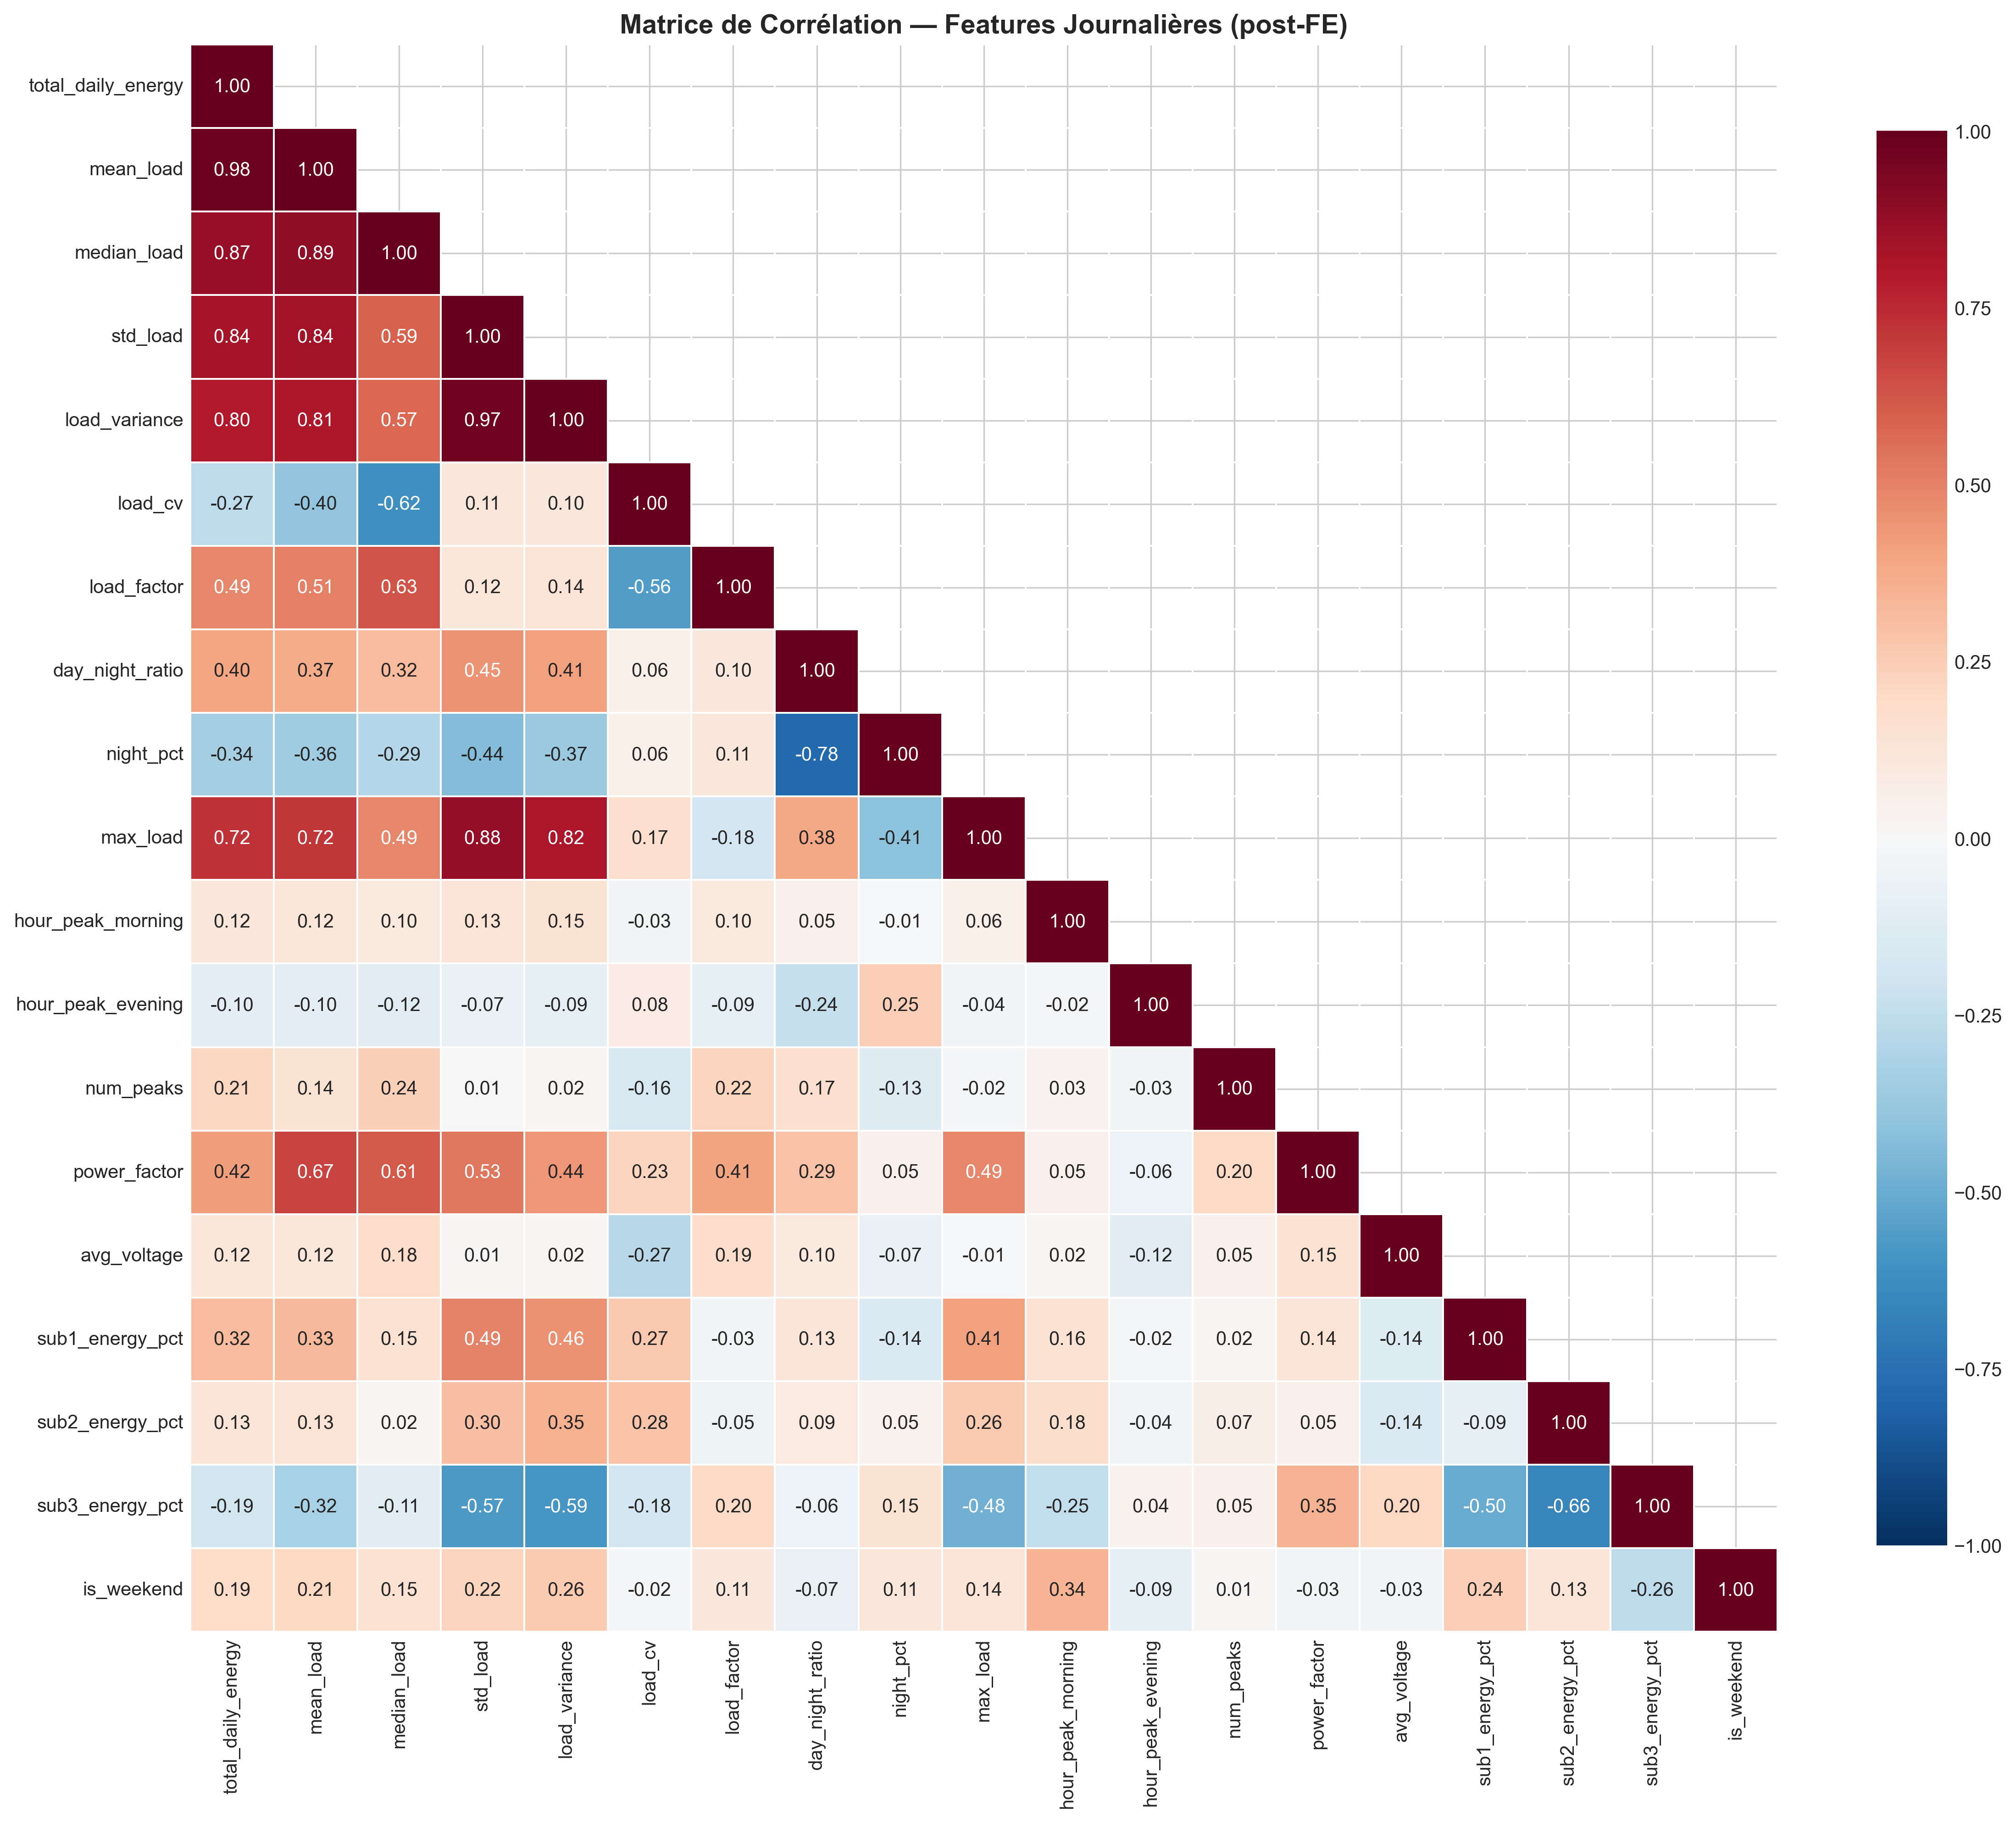

=== Paires fortement corrélées (|r| > 0.85) ===
  total_daily_energy ↔ mean_load: r=0.984
  total_daily_energy ↔ median_load: r=0.875
  mean_load ↔ median_load: r=0.890
  std_load ↔ load_variance: r=0.969
  std_load ↔ max_load: r=0.879


In [22]:
# FIGURE 4: Matrice de corrélation post-Feature Engineering (Exclure Date et season pour cette partie)

feature_cols = ['total_daily_energy', 'mean_load', 'median_load', 'std_load',
                'load_variance', 'load_cv', 'load_factor', 'day_night_ratio',
                'night_pct', 'max_load', 'hour_peak_morning', 'hour_peak_evening',
                'num_peaks', 'power_factor', 'avg_voltage',
                'sub1_energy_pct', 'sub2_energy_pct', 'sub3_energy_pct', 'is_weekend']

df_corr = df_features[feature_cols].copy()

fig, ax = plt.subplots(figsize=(16, 14))
corr_matrix = df_corr.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, vmin=-1, vmax=1, ax=ax)
ax.set_title('Matrice de Corrélation — Features Journalières (post-FE)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/04_correlation_post_fe.png", dpi=150, bbox_inches='tight')
plt.show()

# Identifier les corrélations élevées
print("=== Paires fortement corrélées (|r| > 0.85) ===")
high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.85:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], r))
            print(f"  {corr_matrix.columns[i]} ↔ {corr_matrix.columns[j]}: r={r:.3f}")



## Eliminations des features redondant 
>total_daily_energy ↔ mean_load: REDONDANT (même info, échelle différente).

>std_load ↔ load_variance: REDONDANT (variance = std²).

>sub3_energy_pct ↔ sub1_energy_pct: CORRÉLATION NÉGATIVE (somme=100%).

> nous Gardons load_cv (ratio) plutôt que std_load + mean_load séparés.

## Élimination des features non transférables

Après analyse, nous décidons de **supprimer** les trois features suivantes de notre jeu de données final :

- `sub1_energie_pct`
- `sub2_energie_pct`
- `power_factor`

### Justification

Ces features, bien qu’intéressantes sur le jeu de données UCI, ne sont **pas transférables** à d’autres jeux de données de consommation électrique (autres maisons, autres sources) pour les raisons suivantes :

| Feature | Raison de la non-transférabilité |
|---------|-----------------------------------|
| `sub1_energie_pct` / `sub2_energie_pct` | Dépendent de la présence des sous‑compteurs `Sub_metering_1` et `Sub_metering_2` spécifiques au dataset UCI. La majorité des compteurs intelligents ne fournissent qu’une consommation totale, sans cette répartition. |
| `power_factor` | Nécessite la puissance réactive (`Global_reactive_power`) ou simultanément la tension et le courant, données rarement disponibles dans les jeux de données réels. |

→ **Ces features ne pourront pas être réutilisées pour un modèle générique ou pour une application sur d’autres foyers.**

### Recommandations

Pour construire un modèle **robuste et généralisable**, nous recommandons de privilégier des features universelles, calculables à partir de la **seule puissance active totale** et de l’**horodatage** :

- Statistiques journalières / horaires : moyenne, médiane, écart‑type, minimum, maximum, quantiles.
- Indicateurs de forme de charge : rapport pic/moyenne, pente en fin de journée, heures de pointe.
- Variables temporelles : jour de la semaine, weekend, mois, saison.
- Agrégats glissants (moyennes mobiles, tendances).

### Option pour les puristes

Si l’objectif est uniquement d’optimiser la segmentation **sur ce jeu de données UCI**, vous pouvez conserver ces features **à titre expérimental** (en les marquant comme non réutilisables).  
Toutefois, pour une approche professionnelle et réutilisable, nous les écartons définitivement du jeu de features final.

---

**Action** : Supprimer les colonnes `sub1_energie_pct`, `sub2_energie_pct` et `power_factor` du DataFrame final avant la normalisation et le clustering.


# SÉLECTION FEATURES FINALES + NORMALISATION

## Sélection et Optimisation des Variables (Feature Selection)

La phase de construction des variables a généré un large ensemble de caractéristiques décrivant la consommation électrique. Afin d'optimiser la performance et l'interprétabilité des futurs modèles de clustering, une étape de **sélection de variables** a été menée. L'objectif est de réduire la dimensionnalité du jeu de données en éliminant les variables redondantes ou peu informatives (faible variance).

### Analyse de la redondance et élimination

Le choix des variables finales repose sur une analyse de corrélation et de pertinence statistique :

**Élimination par redondance linéaire ** : Des variables corrélées quasi-parfaitement ont été supprimées pour éviter la multicolinéarité. Par exemple, `total_daily_energy` a été écartée au profit de `mean_load` (information équivalente à un facteur d'échelle près), et `median_load` a été retirée au profit de la moyenne. De même, `night_pct` étant parfaitement corrélée à `day_night_ratio` ($r = -0.999$), seule cette dernière a été conservée.
**Élimination par pertinence physique** : `load_variance` a été remplacée par `load_cv` (Coefficient de Variation), car ce dernier normalise la dispersion par rapport à la moyenne, offrant une mesure de stabilité plus robuste entre des ménages de tailles différentes. De plus, `avg_voltage` a été écarté, son lien avec la consommation étant jugé physiquement redondant dans ce contexte de profilage.
**Filtrage par variance** : Les variables de position temporelle des pics (`hour_peak_morning`, `hour_peak_evening`) présentaient une variance trop faible pour discriminer efficacement les comportements, et ont donc été exclues du modèle.

### Jeu de variables finales retenu

Les caractéristiques sélectionnées permettent de capturer quatre dimensions essentielles du comportement résidentiel : le niveau de consommation, la stabilité, la forme temporelle et les usages spécifiques.

| Variable | Dimension capturée | Justification |
| --- | --- | --- |
| `mean_load` | Niveau de consommation | Tendance centrale globale. |
| `load_cv` | Stabilité | Dispersion relative (plus robuste que l'écart-type). |
| `load_factor` | Forme de charge | Distingue les profils plats des profils à forts pics. |
| `day_night_ratio` | Comportement | Identifie les rythmes d'activité jour/nuit. |
| `max_load` | Intensité | Pic de puissance de la journée. |
| `num_peaks` | Complexité | Nombre de cycles d'activité distincts. |
| `is_weekend` | Contexte temporel | Distinction entre rythmes hebdomadaires et week-end. |

## ETAPE 9 - NORMALISATION

La performance d'un algorithme de clustering dépend fondamentalement du calcul des distances entre les observations. Si les variables ne sont pas ramenées à des échelles comparables, les variables ayant une grande amplitude (comme `total_daily_energy` en kWh) domineront artificiellement le calcul des distances euclidiennes au détriment des autres.

### Méthode utilisé : StandardScaler (Normalisation Z-score)

La standardisation par Z-score est la méthode privilégiée pour le clustering, car elle présente les avantages suivants :

**Centrage** : Chaque variable est centrée sur une moyenne de 0.
**Réduction** : L'écart-type est ramené à 1.
**Préservation** : Elle conserve la forme de la distribution originale.
**Robustesse** : Contrairement au MinMax, elle est moins sensible aux valeurs extrêmes (outliers).
**Interprétabilité** : Elle permet une interprétation immédiate en termes d'écarts-types par rapport à la moyenne.

La transformation est définie par la formule :

$$z = \frac{x - \mu}{\sigma}$$

Où :

* $\mu$ = moyenne de la variable sur l'ensemble des journées.
* $\sigma$ = écart-type de la variable sur l'ensemble des journées.



In [23]:
print("=== SÉLECTION DES FEATURES FINALES (élimination redondances) ===")
# Features à éliminer par redondance:
# - total_daily_energy (redondant avec mean_load, même info x 1440)
# - load_variance (redondant avec std_load)
# - median_load (redondant avec mean_load, r=0.999)
# - std_load (le CV est plus informatif)
# - avg_voltage (fortement corrélé négativement, info physique redondante)
# - night_pct (redondant avec day_night_ratio, r=-0.999)
# - hour_peak_morning, hour_peak_evening (peu de variance, constants)
features_final = [
    'mean_load',           # Tendance centrale (niveau de consommation)
    'load_cv',             # Dispersion relative (stabilité)
    'load_factor',         # Forme de charge (plat vs pics)
    'day_night_ratio',     # Comportement jour/nuit
    'max_load',            # Pic de consommation
    'num_peaks',           # Complexité du profil
    'is_weekend',          # Contexte temporel
]

print(f"Features sélectionnées ({len(features_final)}):")
for f in features_final:
    print(f"  ✓ {f}")

X = df_features[features_final].copy()

# Vérifier les NaN
print(f"\nNaN dans X: {X.isna().sum().sum()}")
X = X.dropna()
print(f"Dimensions finales: {X.shape}")

# ─── StandardScaler ───
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features_final, index=X.index)

print(f"\n=== Après StandardScaler ===")
print(f"Moyennes: {X_scaled.mean(axis=0).round(3).tolist()}")
print(f"Écarts-types: {X_scaled.std(axis=0).round(3).tolist()}")

# Sauvegarder
X_scaled_df.to_csv(f"{OUT_DIR}/uci_features_scaled.csv", index=False)
df_features.to_csv(f"{OUT_DIR}/uci_features_raw.csv", index=False)
print(f"\n✓ Features sauvegardées dans {OUT_DIR}/")

=== SÉLECTION DES FEATURES FINALES (élimination redondances) ===
Features sélectionnées (7):
  ✓ mean_load
  ✓ load_cv
  ✓ load_factor
  ✓ day_night_ratio
  ✓ max_load
  ✓ num_peaks
  ✓ is_weekend

NaN dans X: 18
Dimensions finales: (1431, 7)

=== Après StandardScaler ===
Moyennes: [-0.0, -0.0, -0.0, 0.0, -0.0, -0.0, -0.0]
Écarts-types: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

✓ Features sauvegardées dans d:\projet\Projet clustering\Projet household clustering\data\processed/


## ETAPE 10 - VALIDATION SCIENTIFIQUE DES FEATURES SELECTIVES
## Justification Scientifique des Features

Cette partie théorique explique les fondements physiques et comportementaux de chaque variable (*feature*) retenue dans le dictionnaire de données final. Il démontre la pertinence de ces métriques pour la segmentation des profils de consommation résidentielle.

### 1. `mean_load` (Puissance moyenne journalière)

* **Pourquoi cette feature existe-t-elle ?** Elle traduit le volume global d'énergie appelé en continu ou en moyenne sur le réseau par un point de livraison donné. Elle est mathématiquement corrélée à l'énergie totale (surface sous la courbe de charge).
* **Que représente-t-elle ?** Elle représente "l'empreinte énergétique" globale du ménage. Elle est directement liée à la taille du foyer, à la surface habitable à chauffer/éclairer, et au taux d'équipement en électroménager.
* **Quel est son intérêt énergétique ?** C'est le discriminateur primaire d'échelle. Il permet au clustering de séparer de manière macroscopique les "gros consommateurs" (grandes maisons, suréquipement) des profils très sobres ou des petits logements.

### 2. `load_cv` (Coefficient de variation de la charge)

* **Pourquoi cette feature existe-t-elle ?** L'écart-type brut dépend de l'échelle de consommation. Le coefficient de variation ($CV = \sigma / \mu$) permet d'isoler la variabilité pure de la courbe, indépendamment du volume moyen consommé.
* **Que représente-t-elle ?** Elle quantifie l'irrégularité temporelle des usages. Un CV faible indique une consommation en "bloc" très stable (talon de consommation fort, chauffage continu), tandis qu'un CV élevé révèle un profil en dents de scie dominé par l'allumage ponctuel de gros appareils.
* **Quel est son intérêt énergétique ?** Il sépare les ménages aux comportements erratiques de ceux ayant des routines constantes, offrant une mesure robuste de la stabilité du réseau face à ce point de livraison.

### 3. `load_factor` (Facteur de charge)

* **Pourquoi cette feature existe-t-elle ?** C'est une métrique fondamentale en génie électrique qui compare la demande moyenne à la demande maximale (pointe).
* **Que représente-t-elle ?** Elle reflète l'efficacité de l'utilisation de la puissance. Un foyer qui consomme un peu d'énergie tout le temps a un facteur de charge élevé. Un foyer qui consomme massivement mais sur une très courte durée a un facteur faible.
* **Quel est son intérêt énergétique ?** Il est crucial pour les gestionnaires de réseau (dimensionnement des transformateurs). Pour le clustering, il isole les ménages problématiques créant des pointes de demande fortes et brèves.

### 4. `day_night_ratio` (Ratio d'activité Jour/Nuit)

* **Pourquoi cette feature existe-t-elle ?** Les rythmes circadiens (éveil/sommeil) et l'ensoleillement dictent l'essentiel de la demande électrique humaine (éclairage, activité, chauffage).
* **Que représente-t-elle ?** Elle traduit directement l'emploi du temps des occupants : présence au domicile en journée (télétravail, retraités, parents au foyer) par rapport au temps de repos nocturne, ou à l'inverse, un travail en horaires décalés (travail posté, veille).
* **Quel est son intérêt énergétique ?** Il permet de segmenter les profils selon leur rythme de vie. Il identifie également les foyers ayant un fort talon de consommation nocturne (chauffe-eau heures creuses, chauffage de nuit, serveurs informatiques).

### 5. `max_load` (Puissance maximale de pointe)

* **Pourquoi cette feature existe-t-elle ?** Elle capture l'appel de puissance le plus extrême sur une fenêtre de 24 heures. Elle est provoquée par le cumul de charges ou le démarrage de moteurs/résistances.
* **Que représente-t-elle ?** Elle illustre la simultanéité des actions (ex: cuisiner au four + lancer une machine à laver + chauffage) ou l'existence d'un appareil très énergivore spécifique au foyer (ex: borne de recharge pour véhicule électrique).
* **Quel est son intérêt énergétique ?** C'est l'indicateur clé du stress imposé au réseau local. Le modèle peut ainsi regrouper les ménages responsables des pics de demande, une information vitale pour les programmes d'effacement tarifaire (*Demand Response*).

### 6. `num_peaks` (Nombre de pics significatifs)

* **Pourquoi cette feature existe-t-elle ?** Le lissage de la courbe de charge permet de détecter les extrema locaux qui dépassent un certain seuil d'intensité et de durée.
* **Que représente-t-elle ?** Elle caractérise la complexité et la fragmentation de la routine quotidienne. Un profil à un seul pic (le soir) suggère une journée d'absence simple (travail/école). Un profil à multiples pics (matin, midi, goûter, soir) indique une présence continue ou des va-et-vient fréquents.
* **Quel est son intérêt énergétique ?** Cette variable enrichit la dimension "comportementale" du clustering en discriminant les foyers par la densité temporelle de leurs activités domestiques.

### 7. `is_weekend` (Indicateur temporel)

* **Pourquoi cette feature existe-t-elle ?** Les rythmes de la société humaine sont structurés autour de la coupure entre la semaine de travail/école et les jours de repos.
* **Que représente-t-elle ?** Elle marque le changement d'état contextuel du foyer, où les horaires de réveil, les temps de présence au domicile et le moment d'exécution des tâches ménagères (ménage, lessive) sont modifiés.
* **Quel est son intérêt énergétique ?** Sans cette variable, l'algorithme pourrait confondre un changement de comportement lié au jour de la semaine avec une anomalie. L'inclure permet de capturer la bimodalité du comportement et d'étudier comment les ménages changent (ou non) de cluster entre la semaine et le week-end.



## Tableau des Paramètres et Seuils

Ce tableau centralise l'ensemble des constantes et des seuils décisionnels configurés au sein de l'algorithme pour l'extraction et le filtrage des variables de forme de charge et de pics.

| Paramètre | Valeur | Description | Justification |
| :--- | :--- | :--- | :--- |
| `Delta_t` | $24/T$ heures | Intervalle entre mesures | Dépend de la fréquence d'échantillonnage de la base de données ($1 \text{ min} = 1/60 \text{ h}$). |
| `k (seuil pics)` | $1.5$ | Facteur multiplicateur de $P_{moy}$ | Permet de capturer les pics significatifs ($>50\%$ au-dessus de la puissance moyenne globale). |
| `distance (pics)` | $30$ points | Distance minimale entre pics | Évite la détection multiple d'un même événement transitoire ($30 \text{ min}$ pour un pas de $1 \text{ min}$). |
| `prominence (pics)`| $0.5 \text{ kW}$ | Prominence minimale | Filtre le bruit de fond et les fluctuations mineures non significatives des petits appareils. |
| `Heure jour` | 6h - 22h | Période diurne | Correspond à la plage standard d'activité domestique et de présence humaine. |
| `Heure nuit` | 22h - 6h | Période nocturne | Correspond aux heures de sommeil, propices à l'évaluation de la charge de base. |
| `P_base` | Percentile 10 | Charge de base | Représente le talon de consommation minimale continue (appareils en veille, réfrigérateur). |
| `delta (actif)` | $0.1 \times P_{moy}$ | Seuil d'activité | Fixe une marge de $10\%$ au-dessus de la charge de base pour discriminer le début d'un usage actif. |

## Gestion des Cas Limites

La préparation des données nécessite le traitement rigoureux des anomalies et des valeurs manquantes afin de garantir la stabilité de l'algorithme de clustering et d'éviter les erreurs d'exécution (telles que les divisions par zéro ou l'introduction de valeurs `NaN` et `inf`).

| Cas limite | Détection | Traitement |
| :--- | :--- | :--- |
| **Journée incomplète** (< 90% mesures) | `T < 0.9 * T_attendu` | Exclusion du dataset ou imputation par interpolation temporelle. |
| **$P_{moy} = 0$** (panne/coupure) | `mean_load == 0` | Exclusion (journée non représentative) ou marquage explicite comme "absence". |
| **$E_{nuit} = 0$** (Division par 0) | `sum_nocturne == 0` | `day_night_ratio = inf` (remplacé par valeur max ou 999), `night_pct = 0`. |
| **Aucun pic détecté** | `num_peaks == 0` | `hour_peak_morning`/`evening = NaN`, `num_peaks = 0` (profil plat). |
| **Données manquantes voltage** | Colonne absente ou `NaN` | `avg_voltage = NaN`, traité lors de l'imputation pré-clustering. |
| **Valeurs aberrantes** (outliers) | Z-score > 3 ou IQR > 1.5 | Winsorisation (écrêtage/clip aux percentiles 1-99) ou transformation log. |

# SYNTHÈSE DU PIPELINE COMPLET

Le pipeline de feature engineering présenté dans ce document constitue une méthodologie complète et reproductible pour la construction de signatures énergétiques à partir de séries temporelles de consommation électrique. La synthèse ci-dessous résume l'ensemble des étapes et leurs interactions.

| Étape | Action | Output | Hypothèse associée |
| :--- | :--- | :--- | :--- |
| 1. Transformation temporelle | Découpage en observations journalières | D groupes de mesures (1/jour) | H1 : Représentativité journalière |
| 2. Variables statistiques | Tendance centrale et dispersion | 6 features (mean, median, std, var, cv, total) | H2 : Stabilité énergétique |
| 3. Forme de charge | Structure temporelle de la consommation | 3 features (LF, DNR, night_pct) | H3 : Comportement résidentiel |
| 4. Variables de pics | Détection et caractérisation des maxima | 4 features (max, pic matin, pic soir, nb pics) | H4 : Routines temporelles |
| 5. Variables électriques | Interprétation métier électrique | 2-5 features (PF, voltage, sub-metering) | H5 : Physique des usages |
| 6. Variables contextuelles | Saisonnalité et calendrier | 3-4 features (saison, weekend, actif) | H6 : Contexte temporel |
| 7. Dataset final | Assemblage des features | Matrice D x N (N = 15-18) | - |
| 8. Corrélations | Analyse de redondance | Matrice de corrélation + paires à traiter | - |
| 9. Normalisation | Standardisation Z-score | Dataset standardisé ($\mu=0, \sigma=1$) | - |
| 10. Validation | Justification scientifique | Dictionnaire + annexe méthodologique | - |

### Points clés de la méthodologie

* **Approche pseudo-longitudinale** : chaque journée constitue une observation indépendante permettant d'atteindre un échantillon statistique suffisant pour le clustering.
* **Multi-dimensionnalité** : les features couvrent 6 dimensions complémentaires (tendance, dispersion, forme, pics, électrique, contexte).
* **Interprétabilité physique** : chaque variable possède une traduction directe en termes de comportement résidentiel ou d'usage électrique.
* **Rigueur méthodologique** : validation par corrélation, normalisation et justification scientifique systématique.
* **Extensibilité** : la méthodologie s'applique directement aux datasets multi-ménages (UK-DALE, AMPds2) sans modification du pipeline.
* **Reproductibilité** : algorithme complet, paramètres explicites et gestion des cas limites documentés.

# 18. CONCLUSION ET PERSPECTIVES

La méthodologie de feature engineering présentée dans ce document établit un cadre rigoureux pour la construction de signatures énergétiques exploitables en segmentation. En découpant une série temporelle longue en observations journalières et en enrichissant chaque observation avec des variables multidimensionnelles physiquement interprétables, cette approche permet de transformer des données brutes en un dataset structuré prêt pour l'analyse de clustering.

### Apports principaux

* **Systématicité** : un pipeline complet couvrant l'ensemble des dimensions pertinentes de la consommation électrique résidentielle
* **Interprétabilité** : chaque feature possède une signification physique et comportementale claire, facilitant l'explication des clusters
* **Validité** : six hypothèses formalisées et justifiées qui structurent la démarche et guident l'interprétation
* **Reproductibilité** : algorithme détaillé, paramètres explicites et gestion des cas limites pour une réplication exacte
* **Transférabilité** : applicable aux datasets UCI, UK-DALE et AMPds2 avec des ajustements minimaux liés à la disponibilité des variables

### Perspectives d'extension

Plusieurs extensions de cette méthodologie peuvent être envisagées pour enrichir l'analyse :

| Extension | Description | Intérêt |
| :--- | :--- | :--- |
| Features fréquentielles | Transformée de Fourier ou ondelettes sur le profil journalier | Capture des périodicités intra-journalières (cycles de chauffage) |
| Features entropiques | Entropie de Shannon ou entropie approximative de la série | Mesure de la complexité et de l'irrégularité du signal |
| Features de transition | Statistiques des différences P(t) - P(t-1) | Caractérise la dynamique des changements de charge |
| Features météorologiques | Intégration de la température extérieure, ensoleillement | Explique la variabilité saisonnière et thermique |
| Features d'occupation | Détection de présence/absence par analyse de la charge de base | Distingue les profils de présence des profils d'absence |
| Deep features | Auto-encodeur ou CNN sur les profils bruts | Extraction automatique de features non linéaires |
> de la phase de feature engineering de mon travail de fin de cycle. 

# REFERENCE

@book{geron2022hands,
  title={Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow},
  author={G{\'e}ron, Aur{\'e}lien},
  year={2022},
  publisher={O'Reilly Media, Inc.},
  edition={3rd}
}

@book{tan2018introduction,
  title={Introduction to data mining},
  author={Tan, Pang-Ning and Steinbach, Michael and Karpatne, Anuj and Kumar, Vipin},
  year={2018},
  publisher={Pearson},
  edition={2nd}
}

